<a href="https://colab.research.google.com/github/angelolucero-cloud/GO-Grupo-2/blob/main/Entrega%202/Parte%20A%20Formulaci%C3%B3n/Entrega-2-Parte-A-Formulacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Primer punto (1/8)
### 1. Balance de inventario por SKU y semana

Se define el balance para cada producto $i$ y semana $t$ del horizonte de planificación.

| Símbolo | Definición |
| :--- | :--- |
| $i$ | Índice del SKU. |
| $t$ | Semana del horizonte, desde 1 hasta 13. |
| $I_{it}$ | Inventario disponible al final de la semana. |
| $B_{it}$ | Pedidos pendientes al final de la semana. |
| $x_{it}$ | Producción antes de descontar la merma. |
| $d_{it}$ | Demanda del SKU durante la semana. |
| $\rho_{\ell(i)}$ | Rendimiento de la línea asignada al SKU. |

La producción útil es $\rho_{\ell(i)}x_{it}$. Por lo tanto, el balance es:

$$
I_{it}-B_{it}
=
I_{i,t-1}-B_{i,t-1}
+\rho_{\ell(i)}x_{it}
-d_{it}
$$

El inventario neto final es igual al inventario neto anterior, más la producción útil, menos la demanda semanal.

Para la primera semana se utilizan el inventario inicial $I_{i0}$ y los pedidos atrasados iniciales $B_{i0}$. Tanto el inventario como los pedidos atrasados son variables no negativas:

$$
I_{it}\geq 0,\qquad B_{it}\geq 0
$$

#### 1.3. Incorporación del rendimiento de producción

El rendimiento $\rho_{\ell(i)}$ representa la proporción de la producción que resulta utilizable en la línea asignada al SKU $i$.

Si la tasa de merma de esa línea es $m_{\ell(i)}$, entonces:

$$
\rho_{\ell(i)}=1-m_{\ell(i)}
$$

Como $x_{it}$ representa la producción antes de descontar la merma, la cantidad disponible para atender la demanda es:

$$
q_{it}=\rho_{\ell(i)}x_{it}
$$

Por ejemplo, con una merma del 2 %, el rendimiento es 0,98. Una producción de 1.000 cajas aporta 980 cajas utilizables al balance de inventario.

En el modelo se utilizarán las tasas de merma estimadas en la Entrega 1. El ejemplo anterior es únicamente ilustrativo.

La merma se incorpora una sola vez mediante el rendimiento aplicado a la producción; no se vuelve a descontar del inventario ni se utiliza para aumentar la demanda.

#### 1.4. Pedidos atrasados y su penalización

La demanda que no se atiende durante una semana se mantiene como un pedido pendiente para las semanas siguientes. Este tratamiento se denomina *backlogging*.

La variable $B_{it}$ representa la cantidad de cajas del SKU $i$ que permanecen pendientes al finalizar la semana $t$:

$$
B_{it}\geq 0
$$

Los atrasos no desaparecen al cambiar de semana: el balance de inventario los arrastra hasta que sean atendidos.

Para representar su costo, se define $p_i$ como la penalización por cada caja pendiente durante una semana. El costo total de los atrasos se incorpora a la función objetivo mediante:

$$
C_{\text{atrasos}}
=
\sum_i \sum_{t=1}^{13} p_i B_{it}
$$

Una caja que permanece pendiente durante varias semanas genera penalización en cada una de ellas. El modelo compara este costo con las demás alternativas de producción e inventario.

In [1]:
import pandas as pd
from urllib.parse import quote

BASE_GITHUB = (
    "https://raw.githubusercontent.com/"
    "angelolucero-cloud/GO-Grupo-2/main/"
)

def cargar_csv(ruta):
    url = BASE_GITHUB + quote(ruta, safe="/")
    return pd.read_csv(url, encoding="utf-8-sig")

tabla_traspaso = cargar_csv(
    "Entrega 2/Parte A Formulación/tabla_traspaso_entrega2.csv"
)

print("Tabla de traspaso cargada automáticamente desde GitHub.")
print("Dimensiones:", tabla_traspaso.shape)
print("\nColumnas:")
print(tabla_traspaso.columns.tolist())

display(tabla_traspaso.head())

Tabla de traspaso cargada automáticamente desde GitHub.
Dimensiones: (117, 14)

Columnas:
['Fecha', 'Horizonte', 'SKU', 'linea_envasado', 'formato_L', 'pronostico_cajas', 'sigma_error_cajas', 'n_errores', 'rho_merma', 'factor_produccion_bruta', 'sobrellenado_mL_botella', 'sobrellenado_L_caja', 'litros_por_caja', 'litros_efectivos_caja']


,Fecha,Horizonte,SKU,linea_envasado,formato_L,pronostico_cajas,sigma_error_cajas,n_errores,rho_merma,factor_produccion_bruta,sobrellenado_mL_botella,sobrellenado_L_caja,litros_por_caja,litros_efectivos_caja
0,2026-09-28,1,CIT-L05,L1,0.5,1392.0,433.148090,8,0.019217,1.019594,5.72,0.06864,6.0,6.06864
1,2026-10-05,2,CIT-L05,L1,0.5,1753.0,261.129962,8,0.019217,1.019594,5.72,0.06864,6.0,6.06864
2,2026-10-12,3,CIT-L05,L1,0.5,2080.0,659.049099,8,0.019217,1.019594,5.72,0.06864,6.0,6.06864
3,2026-10-19,4,CIT-L05,L1,0.5,1740.0,10663.337087,8,0.019217,1.019594,5.72,0.06864,6.0,6.06864
4,2026-10-26,5,CIT-L05,L1,0.5,2042.0,912.031798,8,0.019217,1.019594,5.72,0.06864,6.0,6.06864


In [2]:
datos = tabla_traspaso.copy()

# Comprobar que no existan combinaciones SKU-semana repetidas.
assert not datos.duplicated(["SKU", "Horizonte"]).any(), (
    "Existen registros repetidos para un mismo SKU y semana."
)

# Comprobar que cada SKU tenga las 13 semanas.
semanas_esperadas = set(range(1, 14))

for sku, grupo in datos.groupby("SKU"):
    assert set(grupo["Horizonte"]) == semanas_esperadas, (
        f"Faltan semanas o existen semanas inesperadas para {sku}."
    )

assert datos["pronostico_cajas"].notna().all()
assert (datos["pronostico_cajas"] >= 0).all()
assert datos["rho_merma"].between(0, 1, inclusive="left").all()

# Convertir la tasa de merma en rendimiento.
datos["rendimiento"] = 1 - datos["rho_merma"]

# Conjuntos y parámetros del balance.
SKUS = sorted(datos["SKU"].unique())
SEMANAS = list(range(1, 14))

demanda = datos.set_index(
    ["SKU", "Horizonte"]
)["pronostico_cajas"].to_dict()

rendimiento = datos.set_index(
    ["SKU", "Horizonte"]
)["rendimiento"].to_dict()

print(f"Datos preparados: {len(SKUS)} SKU y {len(SEMANAS)} semanas.")

display(
    datos[
        ["linea_envasado", "rho_merma", "rendimiento"]
    ].drop_duplicates().sort_values("linea_envasado")
)

Datos preparados: 9 SKU y 13 semanas.


,linea_envasado,rho_merma,rendimiento
0,L1,0.019217,0.980783
13,L2,0.031146,0.968854


In [3]:
inventario_inicial = cargar_csv(
    "datos/inventario_inicial.csv"
)

print("Inventario inicial cargado automáticamente desde GitHub.")
print("Dimensiones:", inventario_inicial.shape)
print("\nColumnas:")
print(inventario_inicial.columns.tolist())

display(inventario_inicial)

Inventario inicial cargado automáticamente desde GitHub.
Dimensiones: (9, 5)

Columnas:
['sku', 'inventario_inicial_cajas', 'nivel_servicio_objetivo', 'lead_time_jarabe_semanas', 'lote_minimo_cajas']


,sku,inventario_inicial_cajas,nivel_servicio_objetivo,lead_time_jarabe_semanas,lote_minimo_cajas
0,NEC-D05,1024,0.95,1,350
1,NEC-D15,3162,0.95,1,600
2,NEC-D30,339,0.95,1,140
3,CIT-L05,1217,0.95,1,350
4,CIT-L15,1282,0.95,1,430
5,CIT-L30,255,0.95,1,70
6,FUN-B05,2135,0.92,1,550
7,FUN-B15,1261,0.92,1,360
8,FUN-B30,155,0.92,1,30


In [4]:
assert not inventario_inicial["sku"].duplicated().any(), (
    "Hay SKU repetidos en el inventario inicial."
)

assert set(inventario_inicial["sku"]) == set(SKUS), (
    "Los SKU del inventario inicial y del pronóstico no coinciden."
)

parametros_sku = inventario_inicial.set_index("sku")

stock_inicial = parametros_sku["inventario_inicial_cajas"]

assert stock_inicial.notna().all()
assert (stock_inicial >= 0).all()

I0 = stock_inicial.to_dict()
B0 = {sku: 0.0 for sku in SKUS}
penalizacion_atraso = {sku: 1400.0 for sku in SKUS}

resumen_inicial = pd.DataFrame({
    "Inventario inicial": pd.Series(I0),
    "Atraso inicial": pd.Series(B0),
    "Penalización CLP/caja/semana": pd.Series(penalizacion_atraso)
})

display(resumen_inicial)

,Inventario inicial,Atraso inicial,Penalización CLP/caja/semana
CIT-L05,1217,0.0,1400.0
CIT-L15,1282,0.0,1400.0
CIT-L30,255,0.0,1400.0
FUN-B05,2135,0.0,1400.0
FUN-B15,1261,0.0,1400.0
FUN-B30,155,0.0,1400.0
NEC-D05,1024,0.0,1400.0
NEC-D15,3162,0.0,1400.0
NEC-D30,339,0.0,1400.0


In [5]:
%pip install -q pulp==2.9.0

In [6]:
import pulp as pl

modelo = pl.LpProblem("Planificacion_Bebidas_del_Maipo", pl.LpMinimize)

PARES = [(sku, t) for sku in SKUS for t in SEMANAS]

# Variables expresadas en cajas.
x = pl.LpVariable.dicts("produccion_bruta", PARES, lowBound=0)
I = pl.LpVariable.dicts("inventario", PARES, lowBound=0)
B = pl.LpVariable.dicts("atraso", PARES, lowBound=0)

# Balance por SKU y semana.
for k, sku in enumerate(SKUS):
    for t in SEMANAS:
        inventario_anterior = I0[sku] if t == 1 else I[(sku, t - 1)]
        atraso_anterior = B0[sku] if t == 1 else B[(sku, t - 1)]

        modelo += (
            I[(sku, t)] - B[(sku, t)]
            == inventario_anterior - atraso_anterior
            + rendimiento[(sku, t)] * x[(sku, t)]
            - demanda[(sku, t)],
            f"balance_{k}_{t}"
        )

# Expresión que incorporaremos a la función objetivo completa.
costo_atrasos = pl.lpSum(
    penalizacion_atraso[sku] * B[(sku, t)]
    for sku, t in PARES
)

print("Variables creadas:", len(modelo.variables()))
print("Balances incorporados:", len(modelo.constraints))

print("\nEjemplo de balance:")
print(next(iter(modelo.constraints.values())))

Variables creadas: 351
Balances incorporados: 117

Ejemplo de balance:
-atraso_('CIT_L05',_1) + inventario_('CIT_L05',_1) - 0.9807826423866719*produccion_bruta_('CIT_L05',_1) = -175.0


# Segundo punto (2/8)
### 2. Preparación y enlace con la producción

#### 2.1. Variable binaria de preparación

Se define $y_{it}$ para indicar si se habilita la producción del SKU $i$ durante la semana $t$.

| Valor | Interpretación |
| :--- | :--- |
| $y_{it}=1$ | Se prepara la producción del SKU durante esa semana. |
| $y_{it}=0$ | No se prepara y su producción debe ser cero. |

Su dominio es:

$$
y_{it}\in\{0,1\}
$$

Para vincular esta decisión con la producción se utiliza:

$$
x_{it}\leq M_{it}y_{it}
$$

La cota $M_{it}$ representa un límite superior válido para la producción bruta del SKU durante esa semana. Se deducirá a partir de las capacidades disponibles.

Si $y_{it}=0$, la restricción obliga a que $x_{it}=0$. Si $y_{it}=1$, permite producir hasta $M_{it}$; el lote mínimo se incorporará en el punto 6.

In [7]:
nombres_tablas = [
    "maestro_sku.csv",
    "capacidad_horizonte.csv",
    "setups_cip.csv",
    "compromisos_semana_focal.csv"
]

tablas_modelo = {
    nombre: cargar_csv(f"datos/{nombre}")
    for nombre in nombres_tablas
}

for nombre, tabla in tablas_modelo.items():
    print(f"\nArchivo: {nombre}")
    print("Dimensiones:", tabla.shape)
    print("Columnas:", tabla.columns.tolist())
    display(tabla.head())

print("\nLas cuatro tablas se cargaron automáticamente desde GitHub.")


Archivo: maestro_sku.csv
Dimensiones: (9, 13)
Columnas: ['sku', 'familia', 'nombre_familia', 'sabor', 'formato_L', 'botellas_por_caja', 'litros_por_caja', 'linea_envasado', 'tasa_envasado_cajas_h', 'costo_variable_caja_clp', 'precio_lista_caja_clp', 'costo_inventario_caja_semana_clp', 'penalidad_atraso_caja_semana_clp']


,sku,familia,nombre_familia,sabor,formato_L,botellas_por_caja,litros_por_caja,linea_envasado,tasa_envasado_cajas_h,costo_variable_caja_clp,precio_lista_caja_clp,costo_inventario_caja_semana_clp,penalidad_atraso_caja_semana_clp
0,NEC-D05,NEC,Nectares con pulpa,Durazno,0.5,12,6.0,L1,180,3840,6620,95,1400
1,NEC-D15,NEC,Nectares con pulpa,Durazno,1.5,6,9.0,L2,210,5760,9930,95,1400
2,NEC-D30,NEC,Nectares con pulpa,Durazno,3.0,4,12.0,L2,130,7680,13240,95,1400
3,CIT-L05,CIT,Citricos gasificados,Limon,0.5,12,6.0,L1,180,2820,5320,95,1400
4,CIT-L15,CIT,Citricos gasificados,Limon,1.5,6,9.0,L2,210,4230,7980,95,1400



Archivo: capacidad_horizonte.csv
Dimensiones: (13, 14)
Columnas: ['t', 'fecha_lunes', 'horas_mezcla_regular', 'horas_mezcla_extra_max', 'tasa_mezcla_L_h', 'cip_mezcla_horas', 'horas_L1_regular', 'horas_L1_extra_max', 'horas_L2_regular', 'horas_L2_extra_max', 'costo_hora_extra_L2_clp', 'costo_hora_extra_mezcla_clp', 'mantencion_programada_h_L2', 'mantencion_programada_h_mezcla']


,t,fecha_lunes,horas_mezcla_regular,horas_mezcla_extra_max,tasa_mezcla_L_h,cip_mezcla_horas,horas_L1_regular,horas_L1_extra_max,horas_L2_regular,horas_L2_extra_max,costo_hora_extra_L2_clp,costo_hora_extra_mezcla_clp,mantencion_programada_h_L2,mantencion_programada_h_mezcla
0,1,2026-09-28,55.0,10,2300,1.2,40.0,8,48.0,16,168000,121000,0.0,0.0
1,2,2026-10-05,55.0,10,2300,1.2,40.0,8,48.0,16,168000,121000,0.0,0.0
2,3,2026-10-12,55.0,10,2300,1.2,40.0,8,48.0,16,168000,121000,0.0,0.0
3,4,2026-10-19,55.0,10,2300,1.2,40.0,8,40.0,16,168000,121000,8.0,0.0
4,5,2026-10-26,55.0,10,2300,1.2,40.0,8,48.0,16,168000,121000,0.0,0.0



Archivo: setups_cip.csv
Dimensiones: (9, 5)
Columnas: ['familia_origen', 'familia_destino', 'horas_limpieza_cip', 'costo_cip_clp', 'requiere_cip']


,familia_origen,familia_destino,horas_limpieza_cip,costo_cip_clp,requiere_cip
0,CIT,CIT,0.0,0,0
1,CIT,FUN,1.0,74000,1
2,CIT,NEC,1.0,74000,1
3,FUN,CIT,2.4,177600,1
4,FUN,FUN,0.0,0,0



Archivo: compromisos_semana_focal.csv
Dimensiones: (15, 10)
Columnas: ['orden', 'sku', 'familia', 'linea_envasado', 'cliente', 'cantidad_comprometida_cajas', 'dia_comprometido', 'hora_comprometida', 'peso_prioridad', 'multa_atraso_clp_h']


,orden,sku,familia,linea_envasado,cliente,cantidad_comprometida_cajas,dia_comprometido,hora_comprometida,peso_prioridad,multa_atraso_clp_h
0,OP-001,NEC-D05,NEC,L1,Mayorista Sur,389,2,14:00,1,26000
1,OP-002,NEC-D05,NEC,L1,CD Santiago,509,5,18:00,3,78000
2,OP-003,NEC-D15,NEC,L2,Cadena Retail B,584,5,18:00,4,104000
3,OP-004,NEC-D15,NEC,L2,Cadena Retail A,736,3,18:00,5,130000
4,OP-005,NEC-D30,NEC,L2,CD Santiago,313,3,18:00,3,78000



Las cuatro tablas se cargaron automáticamente desde GitHub.


#### 2.2. Cota superior de producción

Se construye una cota física a partir de la tasa de envasado y las horas disponibles en la línea asignada al SKU:

$$
M_{it}=v_i\left(H_{\ell(i),t}^{reg}+H_{\ell(i),t}^{extra,max}\right)
$$

| Símbolo | Definición |
| :--- | :--- |
| $v_i$ | Tasa de envasado del SKU, en cajas por hora. |
| $H_{\ell(i),t}^{reg}$ | Horas regulares disponibles en su línea y semana. |
| $H_{\ell(i),t}^{extra,max}$ | Máximo de horas extra permitido. |

La cota supone que toda la capacidad de la línea se dedica al SKU, sin descontar preparaciones ni producción de otros productos. Por ello, constituye un límite superior válido; las restricciones de capacidad compartida y preparación limitarán posteriormente la producción efectiva.

Como $x_{it}$ representa producción bruta, esta cota no se multiplica por el rendimiento.

In [8]:
maestro = next(
    tabla for tabla in tablas_modelo.values()
    if {"sku", "tasa_envasado_cajas_h"}.issubset(tabla.columns)
).set_index("sku")

capacidad = next(
    tabla for tabla in tablas_modelo.values()
    if {"t", "horas_L1_regular"}.issubset(tabla.columns)
).set_index("t")

assert maestro.index.is_unique
assert capacidad.index.is_unique
assert set(maestro.index) == set(SKUS)
assert set(capacidad.index) == set(SEMANAS)

M = {}

for sku, t in PARES:
    linea = maestro.loc[sku, "linea_envasado"]
    tasa = float(maestro.loc[sku, "tasa_envasado_cajas_h"])

    horas_regulares = capacidad.loc[t, f"horas_{linea}_regular"]
    horas_extra = capacidad.loc[t, f"horas_{linea}_extra_max"]

    M[(sku, t)] = tasa * (horas_regulares + horas_extra)

tabla_M = pd.DataFrame(
    [(sku, t, valor) for (sku, t), valor in M.items()],
    columns=["SKU", "Semana", "Cota_produccion_bruta"]
)

print("Cotas calculadas:", len(M))
display(tabla_M.pivot(
    index="SKU",
    columns="Semana",
    values="Cota_produccion_bruta"
))

Cotas calculadas: 117


Semana,1,2,3,4,5,6,7,8,9,10,11,12,13
SKU,,,,,,,,,,,,,
CIT-L05,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,7920.0
CIT-L15,13440.0,13440.0,13440.0,11760.0,13440.0,13440.0,13440.0,13440.0,11760.0,13440.0,13440.0,13440.0,11760.0
CIT-L30,8320.0,8320.0,8320.0,7280.0,8320.0,8320.0,8320.0,8320.0,7280.0,8320.0,8320.0,8320.0,7280.0
FUN-B05,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,7920.0
FUN-B15,13440.0,13440.0,13440.0,11760.0,13440.0,13440.0,13440.0,13440.0,11760.0,13440.0,13440.0,13440.0,11760.0
FUN-B30,8320.0,8320.0,8320.0,7280.0,8320.0,8320.0,8320.0,8320.0,7280.0,8320.0,8320.0,8320.0,7280.0
NEC-D05,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,8640.0,7920.0
NEC-D15,13440.0,13440.0,13440.0,11760.0,13440.0,13440.0,13440.0,13440.0,11760.0,13440.0,13440.0,13440.0,11760.0
NEC-D30,8320.0,8320.0,8320.0,7280.0,8320.0,8320.0,8320.0,8320.0,7280.0,8320.0,8320.0,8320.0,7280.0


In [9]:
# Una variable binaria por SKU y semana.
y = pl.LpVariable.dicts(
    "preparacion",
    PARES,
    cat="Binary"
)

# Enlace entre preparación y producción.
for k, sku in enumerate(SKUS):
    for t in SEMANAS:
        modelo += (
            x[(sku, t)] <= M[(sku, t)] * y[(sku, t)],
            f"enlace_{k}_{t}"
        )

print("Variables binarias creadas:", len(y))
print("Variables totales:", len(modelo.variables()))
print("Restricciones totales:", len(modelo.constraints))

print("\nEjemplo de enlace:")
print(modelo.constraints["enlace_0_1"])

Variables binarias creadas: 117
Variables totales: 468
Restricciones totales: 234

Ejemplo de enlace:
-8640.0*preparacion_('CIT_L05',_1) + produccion_bruta_('CIT_L05',_1) <= -0.0


#### 2.3. Interpretación del enlace

Para CIT-L05 en la semana 1, la restricción es:

$$
x_{\text{CIT-L05},1}\leq 8640\,y_{\text{CIT-L05},1}
$$

| Preparación | Consecuencia |
| :--- | :--- |
| $y_{\text{CIT-L05},1}=0$ | La producción debe ser cero. |
| $y_{\text{CIT-L05},1}=1$ | La producción puede alcanzar como máximo 8.640 cajas brutas. |

Este límite corresponde a dedicar al SKU todas las horas disponibles de su línea. La producción efectiva también deberá cumplir las restricciones de capacidad compartida, preparación y mezcla.

### 3. Capacidad de envasado y mezcla

#### 3.1. Recursos y unidades de capacidad

La producción utiliza una mezcladora compartida y dos líneas de envasado. Cada recurso dispone de una capacidad semanal limitada.

| Recurso | Productos que procesa | Tasa de producción |
| :--- | :--- | :--- |
| Mezcladora | Todas las familias y formatos. | 2.300 litros por hora. |
| Línea L1 | SKU de 0,5 litros. | 180 cajas por hora. |
| Línea L2 | SKU de 1,5 litros. | 210 cajas por hora. |
| Línea L2 | SKU de 3,0 litros. | 130 cajas por hora. |

Las horas regulares y los máximos de horas extra se obtienen de `capacidad_horizonte.csv` para cada semana.

Para envasado, la producción bruta se convierte a horas mediante:

$$
\text{Horas de envasado}_{it}=\frac{x_{it}}{v_i}
$$

El consumo de jarabe asociado a esa producción se calcula incluyendo el sobrellenado:

$$
\text{Litros requeridos}_{it}=x_{it}L_i^{ef}
$$

Aquí, $L_i^{ef}$ representa los litros por caja, incluido el sobrellenado, y se obtiene de la tabla de traspaso de la Entrega 1.

Las preparaciones y limpiezas también consumen tiempo. Sus horas se incorporarán junto con las horas de procesamiento en las restricciones de capacidad.

El lead time de una semana del jarabe se incorporará en el punto 6 para vincular temporalmente la mezcla con el envasado.

#### 3.2. Capacidad semanal de envasado

Los SKU asignados a una misma línea comparten sus horas disponibles. Por ello, se suman las horas de producción y de preparación de todos sus productos:

$$
\sum_{i\in S_\ell}
\left(
\frac{x_{it}}{v_i}+s_i y_{it}
\right)
\leq
H_{\ell t}^{reg}+e_{\ell t}
\qquad \forall \ell,t
$$

| Símbolo | Definición |
| :--- | :--- |
| $S_\ell$ | Conjunto de SKU asignados a la línea $\ell$. |
| $x_{it}/v_i$ | Horas de envasado de la producción bruta. |
| $s_i$ | Tiempo de preparación estimado por lote activo del SKU. |
| $y_{it}$ | Variable binaria que activa la preparación. |
| $H_{\ell t}^{reg}$ | Horas regulares disponibles en la semana. |
| $e_{\ell t}$ | Horas extra utilizadas en la línea y semana. |

Las horas extra se limitan mediante:

$$
0\leq e_{\ell t}\leq H_{\ell t}^{extra,max}
$$

**Supuesto de preparación del modelo táctico**

Se utilizará un tiempo de preparación estimado por lote activo, que se determinará a partir de la matriz de limpiezas y de los cambios de formato.

Esta aproximación se documentará porque las limpiezas reales dependen del orden de producción. En la Entrega Final se contrastarán las horas estimadas con las que requiere el secuenciamiento.

L1 procesa únicamente el formato de 0,5 L, por lo que no se le asignarán cambios de formato entre sus SKU. L2 procesa dos formatos y deberá considerar esos cambios.

Las horas regulares del archivo de capacidad se interpretan como horas disponibles. Antes de programar las restricciones se verificará cómo están reflejadas las mantenciones para evitar descontarlas dos veces.

#### 3.3. Capacidad semanal de mezcla

La mezcladora es un recurso compartido por todas las familias. Su capacidad debe cubrir tanto la preparación del jarabe como las limpiezas CIP.

Se definen las siguientes variables:

| Símbolo | Definición |
| :--- | :--- |
| $V_{ft}$ | Litros de jarabe preparados para la familia $f$ durante la semana $t$. |
| $z_{ft}$ | Variable binaria que indica si se prepara jarabe de la familia $f$ en esa semana. |
| $e_{mt}$ | Horas extra utilizadas en la mezcladora durante la semana. |

La restricción de capacidad es:

$$
\frac{\sum_f V_{ft}}{r_{mt}}
+
c_t\sum_f z_{ft}
\leq
H_{mt}^{reg}+e_{mt}
\qquad \forall t
$$

Aquí, $r_{mt}$ es la tasa de mezcla en litros por hora y $c_t$ es el tiempo de CIP asignado por familia activa. Ambos parámetros se obtienen del archivo de capacidad.

Se adopta una aproximación táctica de una campaña por familia activa y semana, reservando un CIP de 1,2 horas por campaña. Esta reserva incluye la primera campaña y no representa la secuencia exacta de cambios entre familias.

Para activar la limpieza cuando se prepara jarabe, se utiliza:

$$
V_{ft}\leq U_t z_{ft}
$$

Una cota física válida para los litros preparados es:

$$
U_t=r_{mt}\left(H_{mt}^{reg}+H_{mt}^{extra,max}\right)
$$

Las horas extra de mezcla están acotadas por:

$$
0\leq e_{mt}\leq H_{mt}^{extra,max}
$$

**Consumo de jarabe y sobrellenado**

La necesidad de jarabe para envasar los SKU de una familia es:

$$
R_{ft}=\sum_{i\in S_f}L_i^{ef}x_{it}
$$

El parámetro $L_i^{ef}$ incluye los litros nominales por caja y el sobrellenado estimado en la Entrega 1.

Los litros preparados $V_{ft}$ y los litros consumidos $R_{ft}$ se vincularán mediante un balance de jarabe en el punto 6, respetando su lead time de una semana.

In [10]:
setups_cip = tablas_modelo["setups_cip.csv"].copy()

print("Tiempos CIP obtenidos de las tablas cargadas desde GitHub.")
print("Columnas de setups_cip.csv:")
print(setups_cip.columns.tolist())

display(setups_cip)

print("\nHoras regulares y mantenciones por semana:")
display(capacidad.filter(regex="regular|mantencion"))

Tiempos CIP obtenidos de las tablas cargadas desde GitHub.
Columnas de setups_cip.csv:
['familia_origen', 'familia_destino', 'horas_limpieza_cip', 'costo_cip_clp', 'requiere_cip']


,familia_origen,familia_destino,horas_limpieza_cip,costo_cip_clp,requiere_cip
0,CIT,CIT,0.0,0,0
1,CIT,FUN,1.0,74000,1
2,CIT,NEC,1.0,74000,1
3,FUN,CIT,2.4,177600,1
4,FUN,FUN,0.0,0,0
5,FUN,NEC,1.4,103600,1
6,NEC,CIT,2.8,207200,1
7,NEC,FUN,2.8,207200,1
8,NEC,NEC,0.0,0,0



Horas regulares y mantenciones por semana:


,horas_mezcla_regular,horas_L1_regular,horas_L2_regular,mantencion_programada_h_L2,mantencion_programada_h_mezcla
t,,,,,
1,55.0,40.0,48.0,0.0,0.0
2,55.0,40.0,48.0,0.0,0.0
3,55.0,40.0,48.0,0.0,0.0
4,55.0,40.0,40.0,8.0,0.0
5,55.0,40.0,48.0,0.0,0.0
6,49.0,40.0,48.0,0.0,6.0
7,55.0,40.0,48.0,0.0,0.0
8,55.0,40.0,48.0,0.0,0.0
9,55.0,40.0,40.0,8.0,0.0


#### 3.4. Parámetros de preparación y capacidad disponible

Las horas regulares del archivo de capacidad ya reflejan las mantenciones programadas, por lo que se utilizan directamente.

Para el modelo táctico se calcula el promedio de los seis tiempos de CIP entre familias distintas:

$$
\bar{s}_{CIP}
=
\frac{1+1+2,4+1,4+2,8+2,8}{6}
=
1,9\text{ horas}
$$

Se reserva este tiempo por cada lote activo de envasado. En L2 se agrega una reserva de 0,6 horas por lote para representar los cambios de formato:

$$
s_i=
\begin{cases}
1,9 & \text{si el SKU pertenece a L1}\\
2,5 & \text{si el SKU pertenece a L2}
\end{cases}
$$

Esta es una aproximación por lote: reserva preparación incluso para el primero de la semana y puede sobreestimar el tiempo cuando se agrupan productos de la misma familia y formato. Tampoco garantiza cubrir todas las secuencias posibles. Su precisión se evaluará mediante el secuenciamiento de la Entrega Final.

La limpieza de la mezcladora se trata por separado, utilizando el parámetro de CIP por familia activa del archivo de capacidad.

In [11]:
cambios_familia = setups_cip[
    setups_cip["familia_origen"] != setups_cip["familia_destino"]
]

cip_promedio = cambios_familia["horas_limpieza_cip"].mean()

linea_sku = maestro["linea_envasado"].to_dict()
familia_sku = maestro["familia"].to_dict()
tasa_envasado = maestro["tasa_envasado_cajas_h"].to_dict()

tiempo_preparacion = {
    sku: cip_promedio + (0.6 if linea_sku[sku] == "L2" else 0.0)
    for sku in SKUS
}

# Verificar que los litros por caja sean constantes para cada SKU.
assert (
    datos.groupby("SKU")["litros_efectivos_caja"]
    .nunique(dropna=False)
    .eq(1)
    .all()
)
assert datos["litros_efectivos_caja"].notna().all()
assert (datos["litros_efectivos_caja"] > 0).all()

litros_efectivos = (
    datos.drop_duplicates("SKU")
    .set_index("SKU")["litros_efectivos_caja"]
    .to_dict()
)

resumen_preparacion = pd.DataFrame({
    "Linea": pd.Series(linea_sku),
    "Preparacion_estimada_h": pd.Series(tiempo_preparacion),
    "Litros_por_caja_con_sobrellenado": pd.Series(litros_efectivos)
})

print(f"CIP promedio entre familias: {cip_promedio:.2f} horas")
display(resumen_preparacion)

CIP promedio entre familias: 1.90 horas


,Linea,Preparacion_estimada_h,Litros_por_caja_con_sobrellenado
CIT-L05,L1,1.9,6.068640
CIT-L15,L2,2.5,9.027798
CIT-L30,L2,2.5,12.033716
FUN-B05,L1,1.9,6.068640
FUN-B15,L2,2.5,9.027798
FUN-B30,L2,2.5,12.033716
NEC-D05,L1,1.9,6.068640
NEC-D15,L2,2.5,9.027798
NEC-D30,L2,2.5,12.033716


In [12]:
LINEAS = ["L1", "L2"]

sku_por_linea = {
    linea: [sku for sku in SKUS if linea_sku[sku] == linea]
    for linea in LINEAS
}

e_linea = {
    (linea, t): pl.LpVariable(
        f"extra_{linea}_{t}",
        lowBound=0,
        upBound=float(capacidad.loc[t, f"horas_{linea}_extra_max"])
    )
    for linea in LINEAS
    for t in SEMANAS
}

horas_envasado = {}

for linea in LINEAS:
    for t in SEMANAS:
        horas_envasado[(linea, t)] = pl.lpSum(
            (1.0 / float(tasa_envasado[sku])) * x[(sku, t)]
            + tiempo_preparacion[sku] * y[(sku, t)]
            for sku in sku_por_linea[linea]
        )

        modelo += (
            horas_envasado[(linea, t)]
            <= float(capacidad.loc[t, f"horas_{linea}_regular"])
            + e_linea[(linea, t)],
            f"capacidad_{linea}_{t}"
        )

print("Restricciones de envasado incorporadas: 26")

Restricciones de envasado incorporadas: 26


In [13]:
FAMILIAS = sorted(set(familia_sku.values()))
PARES_FAMILIA = [(f, t) for f in FAMILIAS for t in SEMANAS]

V = pl.LpVariable.dicts("jarabe_preparado", PARES_FAMILIA, lowBound=0)
z = pl.LpVariable.dicts("familia_activa_mezcla", PARES_FAMILIA, cat="Binary")

e_mezcla = {
    t: pl.LpVariable(
        f"extra_mezcla_{t}",
        lowBound=0,
        upBound=float(capacidad.loc[t, "horas_mezcla_extra_max"])
    )
    for t in SEMANAS
}

horas_mezcla = {}
U_mezcla = {}

for t in SEMANAS:
    tasa = float(capacidad.loc[t, "tasa_mezcla_L_h"])
    cip = float(capacidad.loc[t, "cip_mezcla_horas"])
    horas_reg = float(capacidad.loc[t, "horas_mezcla_regular"])
    extra_max = float(capacidad.loc[t, "horas_mezcla_extra_max"])

    U_mezcla[t] = tasa * (horas_reg + extra_max)

    horas_mezcla[t] = (
        pl.lpSum(V[(f, t)] for f in FAMILIAS) / tasa
        + cip * pl.lpSum(z[(f, t)] for f in FAMILIAS)
    )

    modelo += (
        horas_mezcla[t] <= horas_reg + e_mezcla[t],
        f"capacidad_mezcla_{t}"
    )

    for f in FAMILIAS:
        modelo += (
            V[(f, t)] <= U_mezcla[t] * z[(f, t)],
            f"activar_mezcla_{f}_{t}"
        )

# Consumo de jarabe asociado al envasado.
R = {
    (f, t): pl.lpSum(
        litros_efectivos[sku] * x[(sku, t)]
        for sku in SKUS if familia_sku[sku] == f
    )
    for f, t in PARES_FAMILIA
}

print("Variables totales:", len(modelo.variables()))
print("Restricciones totales:", len(modelo.constraints))

print("\nEjemplo de capacidad de mezcla:")
print(modelo.constraints["capacidad_mezcla_1"])

Variables totales: 585
Restricciones totales: 312

Ejemplo de capacidad de mezcla:
-extra_mezcla_1 + 1.2*familia_activa_mezcla_('CIT',_1) + 1.2*familia_activa_mezcla_('FUN',_1) + 1.2*familia_activa_mezcla_('NEC',_1) + 0.0004347826086956522*jarabe_preparado_('CIT',_1) + 0.0004347826086956522*jarabe_preparado_('FUN',_1) + 0.0004347826086956522*jarabe_preparado_('NEC',_1) <= 55.0


#### 3.5. Revisión de las restricciones de capacidad

Se incorporaron las siguientes restricciones:

| Restricción | Cantidad |
| :--- | ---: |
| Capacidad de envasado: 2 líneas × 13 semanas. | 26 |
| Capacidad de mezcla: 13 semanas. | 13 |
| Activación de mezcla: 3 familias × 13 semanas. | 39 |
| Total agregado en este punto. | 78 |

El modelo acumula 585 variables y 312 restricciones.

Las restricciones de envasado incluyen procesamiento y preparación. Las de mezcla incluyen los litros preparados y los CIP por familia activa. Las horas extra tienen límites superiores definidos por los datos.

La vinculación entre el jarabe preparado y su consumo en envasado se incorporará en el punto 6, respetando el lead time de una semana. La factibilidad del plan se comprobará al resolver el modelo completo.

### 4. Stock de seguridad

#### 4.1. Nivel de servicio e incertidumbre de la demanda

El stock de seguridad es una reserva destinada a cubrir desviaciones de la demanda respecto del pronóstico.

Para calcularlo se utilizan dos parámetros:

| Parámetro | Fuente | Interpretación |
| :--- | :--- | :--- |
| $\alpha_i$ | `inventario_inicial.csv` | Nivel de servicio objetivo del SKU. |
| $\hat{\sigma}_{i,h}$ | Tabla de traspaso de la Entrega 1. | Desviación estándar del error de pronóstico para el SKU y horizonte correspondiente. |

Los niveles de servicio proporcionados son:

| Familia | Nivel de servicio objetivo |
| :--- | ---: |
| CIT | 95 % |
| NEC | 95 % |
| FUN | 92 % |

Para formular la reserva se interpretará $\alpha_i$ como la probabilidad objetivo de cubrir la demanda del período considerado, bajo el supuesto de disponibilidad del abastecimiento planificado. Esta medida es distinta del porcentaje de cajas efectivamente entregadas.

Se utilizará una aproximación normal del error de pronóstico, suponiendo que está centrado en cero y que su desviación estándar está representada por $\hat{\sigma}_{i,h}$.

La desviación estándar se toma para cada semana pronosticada. No se multiplicará automáticamente por la raíz del horizonte: el horizonte del pronóstico no equivale a un período de demanda acumulada.

Antes de imponer restricciones se revisarán los valores calculados y su relación con la demanda y la capacidad disponible.

#### 4.2. Deducción del stock de seguridad

La demanda real se representa como el pronóstico más un error aleatorio:

$$
D_{it}=\hat{d}_{it}+\varepsilon_{it}
$$

Se supone que el error sigue aproximadamente una distribución normal con media cero:

$$
\varepsilon_{it}\sim N\left(0,\hat{\sigma}_{i,h}^{\,2}\right)
$$

Si se dispone del pronóstico más una reserva $SS_{it}$, la condición de cobertura es:

$$
P\left(D_{it}\leq\hat{d}_{it}+SS_{it}\right)\geq\alpha_i
$$

Al sustituir la expresión de la demanda y estandarizar el error:

$$
P\left(
\frac{\varepsilon_{it}}{\hat{\sigma}_{i,h}}
\leq
\frac{SS_{it}}{\hat{\sigma}_{i,h}}
\right)
\geq\alpha_i
$$

Por lo tanto, la reserva mínima bajo estos supuestos es:

$$
SS_{it}=\Phi^{-1}(\alpha_i)\,\hat{\sigma}_{i,h}
$$

La función $\Phi^{-1}$ entrega el cuantil de la distribución normal estándar:

| Nivel de servicio | Cuantil aproximado |
| :--- | ---: |
| 95 % | 1,645 |
| 92 % | 1,405 |

El stock de seguridad se redondeará hacia arriba a cajas completas:

$$
SS_{it}
=
\left\lceil
\Phi^{-1}(\alpha_i)\,\hat{\sigma}_{i,h}
\right\rceil
$$

Esta deducción corresponde a la cobertura de la demanda de una semana. Su aplicación depende de los supuestos sobre el error y de la disponibilidad oportuna del abastecimiento; no garantiza por sí sola el servicio del plan completo.

In [14]:
import numpy as np
from statistics import NormalDist

nivel_servicio = parametros_sku["nivel_servicio_objetivo"].to_dict()

assert all(0.5 < nivel_servicio[sku] < 1 for sku in SKUS)
assert datos["sigma_error_cajas"].notna().all()
assert np.isfinite(datos["sigma_error_cajas"]).all()
assert (datos["sigma_error_cajas"] >= 0).all()

z_servicio = {
    sku: NormalDist().inv_cdf(float(nivel_servicio[sku]))
    for sku in SKUS
}

tabla_SS = datos[
    ["SKU", "Horizonte", "pronostico_cajas", "sigma_error_cajas"]
].copy()

tabla_SS["nivel_servicio"] = tabla_SS["SKU"].map(nivel_servicio)
tabla_SS["z_servicio"] = tabla_SS["SKU"].map(z_servicio)

tabla_SS["stock_seguridad_cajas"] = np.ceil(
    tabla_SS["z_servicio"] * tabla_SS["sigma_error_cajas"]
).astype(int)

# Cociente definido solo cuando el pronóstico es positivo.
tabla_SS["SS_sobre_pronostico"] = (
    tabla_SS["stock_seguridad_cajas"]
    / tabla_SS["pronostico_cajas"].replace(0, np.nan)
)

SS = tabla_SS.set_index(
    ["SKU", "Horizonte"]
)["stock_seguridad_cajas"].to_dict()

print("Reservas calculadas:", len(SS))

print("\nResumen por SKU:")
display(
    tabla_SS.groupby("SKU").agg(
        nivel_servicio=("nivel_servicio", "first"),
        SS_minimo=("stock_seguridad_cajas", "min"),
        SS_promedio=("stock_seguridad_cajas", "mean"),
        SS_maximo=("stock_seguridad_cajas", "max")
    ).round(2)
)

print("\nMayores reservas en relación con el pronóstico:")
display(
    tabla_SS.sort_values(
        "SS_sobre_pronostico", ascending=False
    ).head(10)
)

Reservas calculadas: 117

Resumen por SKU:


,nivel_servicio,SS_minimo,SS_promedio,SS_maximo
SKU,,,,
CIT-L05,0.95,377,3410.15,17540
CIT-L15,0.95,626,975.38,1486
CIT-L30,0.95,89,153.38,188
FUN-B05,0.92,544,849.54,1074
FUN-B15,0.92,270,646.00,1007
FUN-B30,0.92,132,238.15,300
NEC-D05,0.95,247,668.92,1182
NEC-D15,0.95,797,1347.46,1931
NEC-D30,0.95,155,215.77,289



Mayores reservas en relación con el pronóstico:


,SKU,Horizonte,pronostico_cajas,sigma_error_cajas,nivel_servicio,z_servicio,stock_seguridad_cajas,SS_sobre_pronostico
3,CIT-L05,4,1740.000000,10663.337087,0.95,1.644854,17540,10.080460
8,CIT-L05,9,2326.000000,10587.860588,0.95,1.644854,17416,7.487532
86,NEC-D05,9,926.674202,709.392502,0.95,1.644854,1167,1.259342
68,FUN-B30,4,301.000000,210.920601,0.92,1.405072,297,0.986711
97,NEC-D15,7,1798.919911,1068.299246,0.95,1.644854,1758,0.977253
75,FUN-B30,11,324.000000,213.490749,0.92,1.405072,300,0.925926
81,NEC-D05,4,1357.004720,718.141688,0.95,1.644854,1182,0.871036
102,NEC-D15,12,2231.392517,1173.754245,0.95,1.644854,1931,0.865379
101,NEC-D15,11,2043.692530,1039.138120,0.95,1.644854,1710,0.836721
91,NEC-D15,1,1964.866895,991.425780,0.95,1.644854,1631,0.830082


#### 4.3. Revisión de las reservas calculadas

Se obtuvieron 117 valores de stock de seguridad. Destacan CIT-L05 en las semanas 4 y 9, con reservas de 17.540 y 17.416 cajas, respectivamente.

Estos resultados provienen de desviaciones estándar del error superiores a 10.000 cajas. Antes de incorporar las restricciones se revisará su cálculo en la Entrega 1 y la presencia de errores extremos.

Las estimaciones originales se conservan durante la revisión; no se aplican recortes arbitrarios.

#### Diagnóstico de las reservas extremas de CIT-L05

Las reservas elevadas de los horizontes 4 y 9 están dominadas por la venta de 32.916 cajas registrada el 29/12/2025. La misma observación aparece en ambos horizontes por la superposición de las ventanas de evaluación.

Al excluir únicamente esa fecha del cálculo, las reservas disminuyen de 17.540 a 1.181 cajas en el horizonte 4 y de 17.416 a 801 cajas en el horizonte 9. Cada estimación pasa de ocho a siete errores.

Esta comparación demuestra sensibilidad a una observación extrema, pero no prueba que el registro sea incorrecto. Se conservan las estimaciones originales como escenario base y se documenta la alternativa para analizar su impacto en la planificación.

#### 4.4. Incorporación de la reserva y tratamiento de su incumplimiento

Se define $u_{it}\geq 0$ como el déficit respecto del stock de seguridad, medido sobre el inventario neto:

$$
I_{it}-B_{it}+u_{it}\geq SS_{it}
$$

Si el inventario neto alcanza la reserva, el déficit puede ser cero. Si queda por debajo, $u_{it}$ mide la distancia hasta la meta.

Esta formulación mantiene el backlogging permitido y permite identificar reservas que no pueden alcanzarse con la capacidad disponible. El cumplimiento del nivel de servicio no queda garantizado por esta restricción flexible.

El déficit se penaliza en la función objetivo:

$$
C_{\text{déficit de reserva}}
=
\sum_i\sum_t q_i u_{it}
$$

El enunciado no entrega un costo específico para incumplir la reserva. Como supuesto de política inicial, se adopta $q_i=1.400$ CLP por caja y semana, utilizando la penalidad de atraso como referencia. Su efecto deberá analizarse mediante sensibilidad.

Como el déficit se mide sobre inventario neto, un pedido atrasado aumenta tanto el costo de backlogging como el déficit de reserva. Por tanto, mientras ambas penalizaciones estén activas, el costo marginal conjunto del atraso será de 2.800 CLP por caja y semana.

In [15]:
u_SS = pl.LpVariable.dicts(
    "deficit_reserva",
    PARES,
    lowBound=0
)

# Supuesto de política, documentado para su sensibilidad.
penalizacion_reserva = {sku: 1400.0 for sku in SKUS}

for k, sku in enumerate(SKUS):
    for t in SEMANAS:
        modelo += (
            I[(sku, t)] - B[(sku, t)] + u_SS[(sku, t)]
            >= float(SS[(sku, t)]),
            f"meta_reserva_{k}_{t}"
        )

costo_deficit_reserva = pl.lpSum(
    penalizacion_reserva[sku] * u_SS[(sku, t)]
    for sku, t in PARES
)

print("Metas de reserva incorporadas:", len(PARES))
print("Variables totales:", len(modelo.variables()))
print("Restricciones totales:", len(modelo.constraints))

Metas de reserva incorporadas: 117
Variables totales: 702
Restricciones totales: 429


### 5. Horas extra como decisión de producción

#### 5.1. Variables, límites y costos

Las horas extra permiten ampliar la capacidad semanal de los recursos. Sus variables ya se incorporaron a las restricciones de envasado y mezcla.

| Recurso | Variable | Límite |
| :--- | :--- | :--- |
| Línea L1 | $e_{L1,t}$ | Máximo semanal indicado en el archivo de capacidad. |
| Línea L2 | $e_{L2,t}$ | Máximo semanal indicado en el archivo de capacidad. |
| Mezcladora | $e_{mt}$ | Máximo semanal indicado en el archivo de capacidad. |

Para cada recurso $r$ y semana $t$:

$$
0\leq e_{rt}\leq H_{rt}^{extra,max}
$$

Su contribución al costo total es:

$$
C_{\text{horas extra}}
=
\sum_{t=1}^{13}
\left(
c_{L1,t}e_{L1,t}
+c_{L2,t}e_{L2,t}
+c_{m,t}e_{mt}
\right)
$$

El archivo proporciona un costo de 168.000 CLP por hora extra de L2 y 121.000 CLP por hora extra de mezcla.

No aparece un costo explícito para las horas extra de L1 en el enunciado ni en las columnas del archivo de capacidad. Este parámetro requiere un supuesto documentado antes de completar el costo de horas extra; no debe interpretarse como cero.

#### 5.2. Supuesto para el costo de horas extra de L1

Ante la ausencia de una tarifa específica para L1, se adopta como referencia inicial la tarifa de horas extra de L2.

Este supuesto permite valorar económicamente las horas adicionales de ambas líneas de envasado. No constituye un dato observado ni implica que sus costos reales sean iguales.

| Recurso | Costo por hora extra | Fuente |
| :--- | ---: | :--- |
| L1 | Tarifa de L2: 168.000 CLP en el escenario base. | Supuesto de referencia. |
| L2 | 168.000 CLP. | Archivo de capacidad. |
| Mezcladora | 121.000 CLP. | Archivo de capacidad. |

Se analizará la sensibilidad del plan a la tarifa asumida para L1.

In [16]:
# Supuesto: L1 utiliza inicialmente el 100 % de la tarifa de L2.
factor_tarifa_L1 = 1.0

costo_extra_linea = {}
costo_extra_mezcla = {}

for t in SEMANAS:
    tarifa_L2 = float(capacidad.loc[t, "costo_hora_extra_L2_clp"])

    costo_extra_linea[("L1", t)] = factor_tarifa_L1 * tarifa_L2
    costo_extra_linea[("L2", t)] = tarifa_L2

    costo_extra_mezcla[t] = float(
        capacidad.loc[t, "costo_hora_extra_mezcla_clp"]
    )

resumen_costos_extra = pd.DataFrame({
    "Semana": SEMANAS,
    "Tarifa_L1_CLP_h": [
        costo_extra_linea[("L1", t)] for t in SEMANAS
    ],
    "Tarifa_L2_CLP_h": [
        costo_extra_linea[("L2", t)] for t in SEMANAS
    ],
    "Tarifa_mezcla_CLP_h": [
        costo_extra_mezcla[t] for t in SEMANAS
    ]
})

display(resumen_costos_extra)

,Semana,Tarifa_L1_CLP_h,Tarifa_L2_CLP_h,Tarifa_mezcla_CLP_h
0,1,168000.0,168000.0,121000.0
1,2,168000.0,168000.0,121000.0
2,3,168000.0,168000.0,121000.0
3,4,168000.0,168000.0,121000.0
4,5,168000.0,168000.0,121000.0
5,6,168000.0,168000.0,121000.0
6,7,168000.0,168000.0,121000.0
7,8,168000.0,168000.0,121000.0
8,9,168000.0,168000.0,121000.0
9,10,168000.0,168000.0,121000.0


In [17]:
costo_extra_envasado = pl.lpSum(
    costo_extra_linea[(linea, t)] * e_linea[(linea, t)]
    for linea in LINEAS
    for t in SEMANAS
)

costo_extra_mezcla_total = pl.lpSum(
    costo_extra_mezcla[t] * e_mezcla[t]
    for t in SEMANAS
)

costo_horas_extra = (
    costo_extra_envasado + costo_extra_mezcla_total
)

print("Variables de horas extra valoradas:",
      len(e_linea) + len(e_mezcla))
print("Costo de horas extra preparado para la función objetivo.")

Variables de horas extra valoradas: 39
Costo de horas extra preparado para la función objetivo.


### 6. Lote mínimo y lead time del jarabe

#### 6.1. Lote mínimo por SKU

Cuando se prepara un SKU, la cantidad producida debe alcanzar su lote mínimo. Si no se prepara, su producción debe ser cero.

Se utiliza el parámetro $L_i^{min}$ del archivo `inventario_inicial.csv`.

En esta formulación se interpreta el lote mínimo como cajas de producción bruta, coherentemente con la definición de $x_{it}$.

$$
x_{it}\geq L_i^{min}y_{it}
$$

Junto con el enlace del punto 2:

$$
L_i^{min}y_{it}\leq x_{it}\leq M_{it}y_{it}
$$

| Preparación | Producción permitida |
| :--- | :--- |
| $y_{it}=0$ | Producción igual a cero. |
| $y_{it}=1$ | Producción entre el lote mínimo y la cota de capacidad. |

Esta restricción evita activar preparaciones con cantidades inferiores al lote mínimo.

#### 6.2. Lead time del jarabe

El jarabe requiere una semana de preparación. Por lo tanto, el jarabe preparado durante la semana $t$ estará disponible para envasar desde la semana $t+1$.

Definimos:

| Símbolo | Descripción |
|---|---|
| $V_{f,t}$ | Litros de jarabe de la familia $f$ preparados en la semana $t$. |
| $R_{f,t}$ | Litros de jarabe requeridos para envasar los productos de la familia $f$ en la semana $t$. |
| $J_{f,t}$ | Inventario de jarabe disponible al finalizar la semana $t$. |

El consumo de jarabe depende de la producción bruta y de los litros efectivos por caja, incluyendo el sobrellenado:

$$
R_{f,t}=\sum_{i\in f}\ell_i^{ef}\,x_{i,t}
$$

Para las semanas 2 a 13, el balance es:

$$
J_{f,t}=J_{f,t-1}+V_{f,t-1}-R_{f,t}
$$

Además:

$$
J_{f,t}\geq 0
$$

Así, el modelo solo puede envasar si dispone de jarabe preparado previamente.

**Condición inicial:** los archivos revisados informan inventario inicial de producto terminado, pero no existencias de jarabe ni preparaciones pendientes de la semana anterior. Para el escenario base, se supone que ambas cantidades son cero:

$$
J_{f,1}=0-R_{f,1}
$$

Como el inventario de jarabe no puede ser negativo, este supuesto impide envasar durante la primera semana. La demanda de esa semana se atiende con el inventario inicial de producto terminado y, si este no alcanza, se registra atraso.

Este supuesto deberá declararse al interpretar los resultados y podrá revisarse mediante un escenario con disponibilidad inicial de jarabe.

Se permite conservar jarabe entre semanas. Al no disponer de información adicional, no se incorporan límites de almacenamiento ni vencimiento.

In [18]:
# 1. Lotes mínimos: cajas de producción bruta
lote_minimo = parametros_sku["lote_minimo_cajas"].to_dict()

for k, sku in enumerate(SKUS):
    for t in SEMANAS:
        modelo += (
            x[sku, t] >= float(lote_minimo[sku]) * y[sku, t],
            f"lote_minimo_{k}_{t}"
        )

# 2. Inventario de jarabe disponible al cierre de cada semana
J = pl.LpVariable.dicts(
    "inventario_jarabe",
    PARES_FAMILIA,
    lowBound=0
)

# Supuestos iniciales, expresados en litros
jarabe_inicial = {f: 0.0 for f in FAMILIAS}
jarabe_pendiente_inicial = {f: 0.0 for f in FAMILIAS}

# 3. Balance con lead time de una semana
for f in FAMILIAS:
    for t in SEMANAS:
        if t == 1:
            disponible = (
                jarabe_inicial[f]
                + jarabe_pendiente_inicial[f]
            )
        else:
            disponible = J[f, t - 1] + V[f, t - 1]

        modelo += (
            J[f, t] == disponible - R[f, t],
            f"balance_jarabe_{f}_{t}"
        )

print("Restricciones de lote mínimo incorporadas:", len(PARES))
print("Balances de jarabe incorporados:", len(PARES_FAMILIA))
print("Variables del modelo:", len(modelo.variables()))
print("Restricciones del modelo:", len(modelo.constraints))

Restricciones de lote mínimo incorporadas: 117
Balances de jarabe incorporados: 39
Variables del modelo: 741
Restricciones del modelo: 585


In [19]:
revision_lotes = parametros_sku[
    ["lote_minimo_cajas", "lead_time_jarabe_semanas"]
].copy()

revision_lotes["menor_M_del_horizonte"] = [
    min(M[sku, t] for t in SEMANAS)
    for sku in revision_lotes.index
]

revision_lotes["lote_compatible_con_M"] = (
    revision_lotes["lote_minimo_cajas"]
    <= revision_lotes["menor_M_del_horizonte"]
)

display(revision_lotes)

assert (
    revision_lotes["lead_time_jarabe_semanas"] == 1
).all(), "Hay SKU cuyo lead time no es de una semana."

assert revision_lotes["lote_compatible_con_M"].all(), (
    "Hay lotes mínimos que superan el límite M."
)

print("Revisión completada: lotes compatibles con M y lead time de una semana.")

,lote_minimo_cajas,lead_time_jarabe_semanas,menor_M_del_horizonte,lote_compatible_con_M
sku,,,,
NEC-D05,350,1,7920.0,True
NEC-D15,600,1,11760.0,True
NEC-D30,140,1,7280.0,True
CIT-L05,350,1,7920.0,True
CIT-L15,430,1,11760.0,True
CIT-L30,70,1,7280.0,True
FUN-B05,550,1,7920.0,True
FUN-B15,360,1,11760.0,True
FUN-B30,30,1,7280.0,True


Revisión completada: lotes compatibles con M y lead time de una semana.


### 7. Inventario terminal y efecto de fin de horizonte

#### 7.1. ¿Por qué se necesita una condición terminal?

El modelo considera 13 semanas. Si solo se contabilizan los costos y la demanda de ese período, puede resultar conveniente terminar la última semana con existencias muy bajas, porque el modelo no observa las necesidades posteriores.

Este comportamiento se denomina efecto de fin de horizonte. En este caso resulta especialmente relevante porque el término del período de planificación antecede al pico de verano de las familias CIT y FUN.

Para evitar el agotamiento artificial de existencias, se establecerá una reserva mínima al finalizar la semana 13:

$$
I_{i,13}-B_{i,13}\geq T_i
$$

donde:

| Símbolo | Descripción |
|---|---|
| $I_{i,13}$ | Inventario de producto terminado del SKU $i$ al finalizar la semana 13. |
| $B_{i,13}$ | Demanda pendiente del SKU $i$ al finalizar la semana 13. |
| $T_i$ | Reserva terminal mínima definida para el SKU $i$. |

La restricción se aplica al inventario neto de atrasos, para evitar que existencias comprometidas con demanda pendiente se contabilicen como reserva disponible.

La reserva terminal es una condición obligatoria de cierre. Se diferencia de las metas semanales de stock de seguridad, cuyo incumplimiento se permite mediante una penalización.

Como la tabla de traspaso contiene pronósticos únicamente hasta la semana 13, la reserva deberá definirse mediante una regla explícita y evaluar su impacto. No se presentará como un pronóstico de semanas posteriores.

#### 7.2. Regla para definir la reserva terminal

Se utilizará el promedio de los pronósticos de las últimas cuatro semanas como referencia del consumo semanal al cierre del horizonte:

$$
\bar{d}_i=\frac{1}{4}\sum_{t=10}^{13}\hat{d}_{i,t}
$$

La reserva terminal se calculará mediante:

$$
T_i=\left\lceil c_i\,\bar{d}_i\right\rceil
$$

donde $c_i$ representa las semanas de cobertura exigidas:

| Familia | Cobertura terminal | Criterio |
|---|---:|---|
| CIT | 1 semana | Mayor protección antes del pico de verano. |
| FUN | 1 semana | Mayor protección antes del pico de verano. |
| NEC | 0,5 semanas | Reserva de continuidad operativa. |

Las cantidades se redondean hacia arriba y se expresan en cajas de producto terminado, por lo que no se ajustan nuevamente por merma.

**Supuesto de planificación:** estas coberturas son una política propuesta para el escenario base; no corresponden a valores entregados por el enunciado. El promedio de las semanas 10 a 13 es una referencia y no un pronóstico de la demanda posterior ni una estimación del aumento estacional.

La reserva terminal no se suma automáticamente al stock de seguridad: ambas condiciones actúan sobre el mismo inventario neto. La reserva terminal constituye un mínimo obligatorio al cierre, mientras que la meta de seguridad puede presentar un déficit penalizado.

Al resolver el modelo se comprobará si esta política es factible con las capacidades disponibles. Posteriormente se compararán sus resultados con un escenario sin reserva terminal y con otras coberturas.

In [20]:
# 1. Coberturas propuestas, expresadas en semanas
cobertura_terminal = {
    "CIT": 1.0,
    "FUN": 1.0,
    "NEC": 0.5
}

# 2. Promedio del pronóstico de las semanas 10 a 13
promedio_demanda_final = {
    sku: sum(float(demanda[sku, t]) for t in range(10, 14)) / 4.0
    for sku in SKUS
}

# 3. Reserva terminal, en cajas de producto terminado
T_terminal = {
    sku: int(np.ceil(
        cobertura_terminal[familia_sku[sku]]
        * promedio_demanda_final[sku]
    ))
    for sku in SKUS
}

# 4. Incorporación de las restricciones
for k, sku in enumerate(SKUS):
    modelo += (
        I[sku, 13] - B[sku, 13] >= T_terminal[sku],
        f"reserva_terminal_{k}"
    )

# 5. Resumen de la política
tabla_terminal = pd.DataFrame([
    {
        "SKU": sku,
        "Familia": familia_sku[sku],
        "Demanda_promedio_semanas_10_13": promedio_demanda_final[sku],
        "Cobertura_semanas": cobertura_terminal[familia_sku[sku]],
        "Reserva_terminal_cajas": T_terminal[sku]
    }
    for sku in SKUS
])

display(tabla_terminal.round(2))

print("Restricciones terminales incorporadas:", len(SKUS))
print("Variables del modelo:", len(modelo.variables()))
print("Restricciones del modelo:", len(modelo.constraints))

,SKU,Familia,Demanda_promedio_semanas_10_13,Cobertura_semanas,Reserva_terminal_cajas
0,CIT-L05,CIT,2544.50,1.0,2545
1,CIT-L15,CIT,3009.90,1.0,3010
2,CIT-L30,CIT,580.25,1.0,581
3,FUN-B05,FUN,2685.72,1.0,2686
4,FUN-B15,FUN,1808.52,1.0,1809
5,FUN-B30,FUN,81.00,1.0,81
6,NEC-D05,NEC,1208.01,0.5,605
7,NEC-D15,NEC,2068.83,0.5,1035
8,NEC-D30,NEC,485.92,0.5,243


Restricciones terminales incorporadas: 9
Variables del modelo: 741
Restricciones del modelo: 594


#### 7.3. Revisión de la condición terminal

Se incorporaron nueve restricciones de reserva terminal, una por SKU. Los mínimos exigidos al finalizar la semana 13 son:

| SKU | Reserva terminal (cajas) |
|---|---:|
| CIT-L05 | 2545 |
| CIT-L15 | 3010 |
| CIT-L30 | 581 |
| FUN-B05 | 2686 |
| FUN-B15 | 1809 |
| FUN-B30 | 81 |
| NEC-D05 | 605 |
| NEC-D15 | 1035 |
| NEC-D30 | 243 |

Estas cantidades son mínimos de inventario neto de atrasos, no resultados de producción ni inventarios obtenidos al resolver el modelo.

La revisión confirma que se aplicó la regla de cobertura propuesta. Su factibilidad y su efecto sobre los costos, la producción y las horas extra se comprobarán al resolver y comparar escenarios.

Esta política reduce el incentivo a agotar el producto terminado al cierre, pero no garantiza por sí sola la cobertura del pico de verano ni establece una reserva de jarabe para semanas posteriores.

### 8. Compromisos de producción de la semana focal

#### 8.1. Producción mínima comprometida

La semana 12, correspondiente al lunes 14 de diciembre de 2026, debe cumplir los compromisos establecidos en el archivo `compromisos_semana_focal.csv`.

Se define $C_i$ como la cantidad de cajas comprometidas para el SKU $i$ en esa semana.

Como $x_{i,12}$ representa producción bruta, se aplica el rendimiento para expresar la producción disponible como producto terminado:

$$
r_{i,12}\,x_{i,12}\geq C_i
$$

donde $r_{i,12}$ es el rendimiento del SKU después de considerar la merma.

**Criterio de interpretación:** los compromisos se consideran cajas de producto terminado. Esta interpretación se contrastará con las columnas y unidades del archivo.

La condición exige producir durante la semana 12. Por lo tanto, el inventario acumulado en semanas anteriores no sustituye esta obligación de producción.

Los compromisos se incorporan como un mínimo de producción y no se suman automáticamente al pronóstico de demanda, para evitar contabilizarlos dos veces. Cualquier indicación de que corresponden a demanda adicional deberá revisarse antes de modificar el balance.

In [21]:
compromisos = tablas_modelo["compromisos_semana_focal.csv"].copy()

print("Compromisos cargados automáticamente desde GitHub.")
print("Dimensiones:", compromisos.shape)
print("Columnas:", compromisos.columns.tolist())

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(compromisos)

Compromisos cargados automáticamente desde GitHub.
Dimensiones: (15, 10)
Columnas: ['orden', 'sku', 'familia', 'linea_envasado', 'cliente', 'cantidad_comprometida_cajas', 'dia_comprometido', 'hora_comprometida', 'peso_prioridad', 'multa_atraso_clp_h']


,orden,sku,familia,linea_envasado,cliente,cantidad_comprometida_cajas,dia_comprometido,hora_comprometida,peso_prioridad,multa_atraso_clp_h
0,OP-001,NEC-D05,NEC,L1,Mayorista Sur,389,2,14:00,1,26000
1,OP-002,NEC-D05,NEC,L1,CD Santiago,509,5,18:00,3,78000
2,OP-003,NEC-D15,NEC,L2,Cadena Retail B,584,5,18:00,4,104000
3,OP-004,NEC-D15,NEC,L2,Cadena Retail A,736,3,18:00,5,130000
4,OP-005,NEC-D30,NEC,L2,CD Santiago,313,3,18:00,3,78000
5,OP-006,CIT-L05,CIT,L1,CD Santiago,347,4,18:00,3,78000
6,OP-007,CIT-L05,CIT,L1,Cadena Retail B,492,4,18:00,4,104000
7,OP-008,CIT-L15,CIT,L2,Mayorista Sur,472,3,18:00,1,26000
8,OP-009,CIT-L15,CIT,L2,Mayorista Sur,554,3,14:00,1,26000
9,OP-010,CIT-L30,CIT,L2,Cadena Retail B,157,4,10:00,4,104000


In [22]:
# 1. Validar los datos antes de agrupar
compromisos["cantidad_comprometida_cajas"] = pd.to_numeric(
    compromisos["cantidad_comprometida_cajas"],
    errors="raise"
)

assert compromisos["sku"].notna().all(), "Hay órdenes sin SKU."
assert compromisos["cantidad_comprometida_cajas"].notna().all(), (
    "Hay órdenes sin cantidad comprometida."
)
assert (compromisos["cantidad_comprometida_cajas"] >= 0).all(), (
    "Hay cantidades comprometidas negativas."
)

sku_desconocidos = set(compromisos["sku"]) - set(SKUS)
assert not sku_desconocidos, (
    f"Hay SKU que no existen en el modelo: {sku_desconocidos}"
)

# 2. Sumar todas las órdenes de cada SKU
C_compromisos = (
    compromisos.groupby("sku")["cantidad_comprometida_cajas"]
    .sum()
    .to_dict()
)

# 3. Exigir producción terminada suficiente en la semana 12
for k, sku in enumerate(SKUS):
    if sku in C_compromisos:
        modelo += (
            rendimiento[sku, 12] * x[sku, 12]
            >= float(C_compromisos[sku]),
            f"compromiso_semana_12_{k}"
        )

# 4. Mostrar las cantidades comprometidas
tabla_compromisos = pd.DataFrame([
    {
        "SKU": sku,
        "Compromiso_producto_terminado_cajas": cantidad,
        "Produccion_bruta_minima_cajas": (
            float(cantidad) / float(rendimiento[sku, 12])
        )
    }
    for sku, cantidad in sorted(C_compromisos.items())
])

display(tabla_compromisos.round(2))

print("Órdenes consideradas:", len(compromisos))
print("Restricciones de compromisos incorporadas:", len(C_compromisos))
print("Variables del modelo:", len(modelo.variables()))
print("Restricciones del modelo:", len(modelo.constraints))

,SKU,Compromiso_producto_terminado_cajas,Produccion_bruta_minima_cajas
0,CIT-L05,839,855.44
1,CIT-L15,1026,1058.98
2,CIT-L30,157,162.05
3,FUN-B05,1340,1366.26
4,FUN-B15,860,887.65
5,FUN-B30,66,68.12
6,NEC-D05,898,915.60
7,NEC-D15,1320,1362.43
8,NEC-D30,313,323.06


Órdenes consideradas: 15
Restricciones de compromisos incorporadas: 9
Variables del modelo: 741
Restricciones del modelo: 603


#### 8.2. Revisión de los compromisos incorporados

Las 15 órdenes del archivo se agruparon por SKU, generando nueve restricciones de producción mínima para la semana 12.

| SKU | Compromiso total de producto terminado (cajas) |
|---|---:|
| CIT-L05 | 839 |
| CIT-L15 | 1026 |
| CIT-L30 | 157 |
| FUN-B05 | 1340 |
| FUN-B15 | 860 |
| FUN-B30 | 66 |
| NEC-D05 | 898 |
| NEC-D15 | 1320 |
| NEC-D30 | 313 |

Las restricciones consideran el rendimiento de cada SKU para convertir la producción bruta en cajas de producto terminado.

El modelo semanal exige cubrir estas cantidades mediante producción de la semana 12. El cumplimiento de los días y horas comprometidos deberá verificarse posteriormente mediante la secuenciación detallada.

La incorporación de las restricciones no demuestra todavía su factibilidad conjunta con las capacidades y las demás condiciones del modelo.

### 9. Función objetivo

El modelo busca minimizar el costo total de planificación durante las 13 semanas:

$$
\min Z =
C_{\text{producción}}
+ C_{\text{inventario}}
+ C_{\text{atrasos}}
+ C_{\text{preparaciones}}
+ C_{\text{horas extra}}
+ C_{\text{déficit de reserva}}
$$

| Componente | Forma de cálculo |
|---|---|
| Producción | Costo variable por caja multiplicado por la producción bruta de cada SKU. |
| Inventario | Costo por caja y semana multiplicado por el inventario final de producto terminado. |
| Atrasos | Penalización por caja y semana multiplicada por la demanda pendiente al cierre. |
| Preparaciones | Costos aproximados de limpieza CIP y cambios de formato asociados a las campañas activadas. |
| Horas extra | Horas extra utilizadas en envasado y mezcla, multiplicadas por sus respectivas tarifas. |
| Déficit de reserva | Penalización por cada caja faltante respecto de la meta semanal de inventario neto. |

#### Criterios de valoración

- El costo variable se aplica a la producción bruta. Se interpreta que los recursos consumidos en unidades que se pierden por merma también generan costos.
- El costo de producción se contabiliza una sola vez: no se añade nuevamente un costo de materiales al volumen de jarabe preparado.
- Los costos de preparación deben ser coherentes con las aproximaciones utilizadas en las restricciones de capacidad. No representan una secuencia exacta de cambios entre productos.
- Para L1 se conserva el supuesto de usar la tarifa de horas extra de L2, dado que no se dispone de una tarifa específica.
- Se mantiene la penalización propuesta de 1400 CLP por caja y semana de déficit de reserva. Es un supuesto de política, adicional a la penalización por atraso.
- Cuando un atraso incrementa también el déficit de reserva, ambos conceptos generan penalización.
- No se incorpora un costo de almacenamiento de jarabe, porque no se dispone de una tarifa. Esto constituye una limitación del modelo.
- Las reservas terminales y los compromisos de la semana 12 son restricciones obligatorias; no se permite sustituir su cumplimiento por una penalización.

Los resultados se interpretarán considerando estos supuestos y las sensibilidades correspondientes.

#### 9.1. Valoración aproximada de las preparaciones

En envasado se valoran 1,9 horas de CIP por SKU activo, a 74.000 CLP por hora. Para los SKU de L2 se añade una provisión de 38.000 CLP por cambio de formato por campaña activada.

En mezcla se consideran las 1,2 horas de CIP por familia activa incluidas en la capacidad semanal. Se utiliza como supuesto la misma tarifa de 74.000 CLP por hora.

Estas provisiones son aproximaciones de planificación: incluyen la primera campaña y no reproducen los cambios de una secuencia concreta. Su precisión deberá evaluarse frente a la programación detallada.

In [23]:
# 1. Costos unitarios del maestro
costo_variable = maestro["costo_variable_caja_clp"].to_dict()
costo_mantencion = (
    maestro["costo_inventario_caja_semana_clp"].to_dict()
)

costo_produccion = pl.lpSum(
    float(costo_variable[sku]) * x[sku, t]
    for sku, t in PARES
)

costo_inventario = pl.lpSum(
    float(costo_mantencion[sku]) * I[sku, t]
    for sku, t in PARES
)

# 2. Preparaciones aproximadas de envasado
tarifa_cip_envasado = 74000.0
costo_cambio_formato = 38000.0

costo_preparacion_sku = {
    sku: (
        float(cip_promedio) * tarifa_cip_envasado
        + (
            costo_cambio_formato
            if linea_sku[sku] == "L2"
            else 0.0
        )
    )
    for sku in SKUS
}

costo_preparaciones_envasado = pl.lpSum(
    costo_preparacion_sku[sku] * y[sku, t]
    for sku, t in PARES
)

# 3. CIP de mezcla: tarifa asumida
tarifa_cip_mezcla = 74000.0

costo_preparaciones_mezcla = pl.lpSum(
    tarifa_cip_mezcla
    * float(capacidad.loc[t, "cip_mezcla_horas"])
    * z[f, t]
    for f, t in PARES_FAMILIA
)

costo_preparaciones = (
    costo_preparaciones_envasado
    + costo_preparaciones_mezcla
)

# 4. Reunir todos los componentes
componentes_costo = {
    "Producción": costo_produccion,
    "Inventario": costo_inventario,
    "Atrasos": costo_atrasos,
    "Preparaciones de envasado": costo_preparaciones_envasado,
    "Preparaciones de mezcla": costo_preparaciones_mezcla,
    "Horas extra": costo_horas_extra,
    "Déficit de reserva": costo_deficit_reserva
}

costo_total = pl.lpSum(componentes_costo.values())

# Establecer la función objetivo sin modificar las restricciones
modelo.setObjective(costo_total)

print("Función objetivo incorporada: minimizar el costo total.")
print("Componentes incluidos:")
for nombre in componentes_costo:
    print("-", nombre)

print("Variables del modelo:", len(modelo.variables()))
print("Restricciones del modelo:", len(modelo.constraints))
print("El modelo todavía no se ha resuelto.")

Función objetivo incorporada: minimizar el costo total.
Componentes incluidos:
- Producción
- Inventario
- Atrasos
- Preparaciones de envasado
- Preparaciones de mezcla
- Horas extra
- Déficit de reserva
Variables del modelo: 741
Restricciones del modelo: 603
El modelo todavía no se ha resuelto.


In [24]:
import math

# 1. Verificar la función objetivo
assert modelo.objective is not None, "Falta la función objetivo."
assert modelo.sense == pl.LpMinimize, (
    "El modelo debe minimizar costos."
)

assert all(
    math.isfinite(float(coeficiente))
    for coeficiente in modelo.objective.values()
), "La función objetivo contiene coeficientes no válidos."

# 2. Revisar los grupos de restricciones
grupos_esperados = {
    "Balances de producto terminado": ("balance_", 117),
    "Enlace entre producción y setup": ("enlace_", 117),
    "Capacidad de L1": ("capacidad_L1_", 13),
    "Capacidad de L2": ("capacidad_L2_", 13),
    "Capacidad de mezcla": ("capacidad_mezcla_", 13),
    "Activación de familias en mezcla": ("activar_mezcla_", 39),
    "Metas de stock de seguridad": ("meta_reserva_", 117),
    "Lotes mínimos": ("lote_minimo_", 117),
    "Balances de jarabe": ("balance_jarabe_", 39),
    "Reservas terminales": ("reserva_terminal_", 9),
    "Compromisos de la semana 12": ("compromiso_semana_12_", 9)
}

revision_estructura = []

for grupo, (prefijo, esperado) in grupos_esperados.items():
    # Evitar contar balances de jarabe como producto terminado
    encontrados = sum(
        nombre.startswith(prefijo)
        and not (
            prefijo == "balance_"
            and nombre.startswith("balance_jarabe_")
        )
        for nombre in modelo.constraints
    )

    revision_estructura.append({
        "Grupo": grupo,
        "Esperadas": esperado,
        "Encontradas": encontrados,
        "Correcto": encontrados == esperado
    })

revision_estructura = pd.DataFrame(revision_estructura)
display(revision_estructura)

assert revision_estructura["Correcto"].all(), (
    "Hay diferencias en los grupos de restricciones."
)

# 3. Verificar coeficientes y constantes de las restricciones
for nombre, restriccion in modelo.constraints.items():
    assert math.isfinite(float(restriccion.constant)), (
        f"Constante no válida en {nombre}"
    )
    assert all(
        math.isfinite(float(coeficiente))
        for coeficiente in restriccion.values()
    ), f"Coeficiente no válido en {nombre}"

print("Revisión estructural completada.")
print("Variables:", len(modelo.variables()))
print("Restricciones:", len(modelo.constraints))
print("Componentes de costo:", len(componentes_costo))
print("La factibilidad y la solución se evaluarán en la parte B.")

,Grupo,Esperadas,Encontradas,Correcto
0,Balances de producto terminado,117,117,True
1,Enlace entre producción y setup,117,117,True
2,Capacidad de L1,13,13,True
3,Capacidad de L2,13,13,True
4,Capacidad de mezcla,13,13,True
5,Activación de familias en mezcla,39,39,True
6,Metas de stock de seguridad,117,117,True
7,Lotes mínimos,117,117,True
8,Balances de jarabe,39,39,True
9,Reservas terminales,9,9,True


Revisión estructural completada.
Variables: 741
Restricciones: 603
Componentes de costo: 7
La factibilidad y la solución se evaluarán en la parte B.


# Parte B Resolución y análisis

## 1. Resolución del modelo de planificación

### 1.1. Objetivo de la resolución

Se resolverá el modelo formulado en la parte A para determinar un plan de producción e inventario de costo mínimo durante las 13 semanas.

El modelo combina decisiones continuas, como cantidades de producción y horas extra, con decisiones binarias de preparación. Por ello, corresponde a un modelo de programación lineal entera mixta, denominado MIP.

Se utilizará CBC a través de PuLP. El registro de ejecución permitirá documentar el solver utilizado y evaluar la calidad de la solución.

### Resultados que se reportarán

| Resultado | Interpretación |
|---|---|
| Estado de resolución | Indica si se encontró una solución óptima, una solución factible sin demostrar optimalidad o si se detectó otro estado. |
| Valor objetivo | Costo total del mejor plan factible encontrado. |
| Cota inferior | Límite que el solver establece para el costo óptimo del modelo de minimización. |
| Brecha de optimalidad | Diferencia relativa entre el costo del mejor plan factible y la cota inferior. |
| Tiempo de resolución | Tiempo empleado en ejecutar el solver. |

Encontrar una solución factible no significa necesariamente demostrar que sea óptima. Si la ejecución termina por un límite de tiempo o una tolerancia de brecha, se informará esa condición.

Antes de interpretar el plan, se comprobará que las cantidades obtenidas respeten los balances, las capacidades, los lotes mínimos, la disponibilidad de jarabe, las reservas terminales y los compromisos de la semana 12.

Si el modelo resulta infactible, se investigarán las restricciones y los supuestos que originan el conflicto antes de presentar cantidades como resultados válidos.

In [25]:
from pathlib import Path
from time import perf_counter

# Carpeta para conservar los resultados de la resolución
carpeta_resultados_B = Path("resultados_entrega2")
carpeta_resultados_B.mkdir(parents=True, exist_ok=True)

ruta_log_cbc = carpeta_resultados_B / "cbc_plan_base.log"

# Parámetros de resolución
limite_tiempo_segundos = 120
tolerancia_brecha_relativa = 0.001  # 0,1 %

solver_base = pl.PULP_CBC_CMD(
    msg=True,
    timeLimit=limite_tiempo_segundos,
    gapRel=tolerancia_brecha_relativa,
    threads=1,
    logPath=str(ruta_log_cbc)
)

assert solver_base.available(), (
    "CBC no está disponible. Revisa la instalación de PuLP."
)

assert modelo.objective is not None, (
    "Debes ejecutar primero la formulación de la parte A."
)

print("Solver: CBC mediante PuLP")
print("Versión de PuLP:", pl.__version__)
print("Límite de tiempo:", limite_tiempo_segundos, "segundos")
print("Brecha relativa objetivo:",
      f"{100 * tolerancia_brecha_relativa:.1f} %")
print("Variables del modelo:", len(modelo.variables()))
print("Restricciones del modelo:", len(modelo.constraints))
print("Registro:", ruta_log_cbc)
print("\nConfiguración preparada. El modelo todavía no se ha resuelto.")

Solver: CBC mediante PuLP
Versión de PuLP: 2.9.0
Límite de tiempo: 120 segundos
Brecha relativa objetivo: 0.1 %
Variables del modelo: 741
Restricciones del modelo: 603
Registro: resultados_entrega2/cbc_plan_base.log

Configuración preparada. El modelo todavía no se ha resuelto.


In [26]:
# Eliminar un registro anterior para no confundir ejecuciones
if ruta_log_cbc.exists():
    ruta_log_cbc.unlink()

# Resolver y medir el tiempo transcurrido
inicio_resolucion = perf_counter()

estado_codigo = modelo.solve(solver_base)

tiempo_resolucion = perf_counter() - inicio_resolucion

# Conservar el registro completo
registro_cbc = (
    ruta_log_cbc.read_text(encoding="utf-8", errors="replace")
    if ruta_log_cbc.exists()
    else ""
)

print("Estado informado por PuLP:",
      pl.LpStatus.get(estado_codigo, str(estado_codigo)))

print("Estado de la solución:",
      pl.LpSolution.get(modelo.sol_status, str(modelo.sol_status)))

print(f"Tiempo transcurrido: {tiempo_resolucion:.2f} segundos")

print("\nÚltimas líneas del registro de CBC:")
if registro_cbc:
    print("\n".join(registro_cbc.splitlines()[-35:]))
else:
    print("No se encontró el registro de ejecución.")

/usr/local/lib/python3.13/dist-packages/pulp/apis/coin_api.py:161: UserWarning: `logPath` argument replaces `msg=1`. The output will be redirected to the log file.
  warnings.warn(


Estado informado por PuLP: Optimal
Estado de la solución: Solution Found
Tiempo transcurrido: 120.16 segundos

Últimas líneas del registro de CBC:
Cbc0010I After 13000 nodes, 1244 on tree, 9.8561897e+08 best solution, best possible 9.7727968e+08 (89.09 seconds)
Cbc0012I Integer solution of 9.8260824e+08 found by heuristic after 300297 iterations and 13218 nodes (90.85 seconds)
Cbc0010I After 14000 nodes, 1454 on tree, 9.8260824e+08 best solution, best possible 9.7727968e+08 (95.65 seconds)
Cbc0010I After 15000 nodes, 1944 on tree, 9.8260824e+08 best solution, best possible 9.7734724e+08 (106.75 seconds)
Cbc0010I After 16000 nodes, 2427 on tree, 9.8260824e+08 best solution, best possible 9.7739114e+08 (115.58 seconds)
Cbc0030I Thread 0 used 16465 times,  waiting to start 0.71124053, 113.25901 cpu time, 93416 locks, 2.2018635 locked, 0.014165401 waiting for locks
Cbc0030I Main thread 117.92362 waiting for threads,  32987 locks, 0.026990414 locked, 0.0049090385 waiting for locks
Cbc0020I 

In [27]:
import re

def extraer_numero_log(etiqueta):
    patron = (
        rf"^\s*{re.escape(etiqueta)}:\s*"
        r"([-+]?\d+(?:\.\d*)?(?:[eE][-+]?\d+)?)"
    )
    coincidencias = re.findall(
        patron, registro_cbc, flags=re.MULTILINE
    )
    return float(coincidencias[-1]) if coincidencias else None

objetivo_log = extraer_numero_log("Objective value")
cota_inferior = extraer_numero_log("Lower bound")

# No interpretar valores de variables si no se encontró un plan
assert modelo.sol_status in (
    pl.LpSolutionOptimal,
    pl.LpSolutionIntegerFeasible
), "No hay una solución factible reportada para analizar."

assert objetivo_log is not None, (
    "No se pudo recuperar el objetivo del registro."
)

objetivo_base = float(pl.value(modelo.objective))

# Definimos explícitamente la brecha respecto de la cota inferior
brecha_relativa_base = (
    abs(objetivo_log - cota_inferior)
    / max(abs(cota_inferior), 1e-10)
    if cota_inferior is not None
    else None
)

if "Stopped on time limit" in registro_cbc:
    conclusion_solver = (
        "Solución encontrada; límite de tiempo; "
        "optimalidad no demostrada"
    )
elif "within gap tolerance" in registro_cbc.lower():
    conclusion_solver = (
        "Solución dentro de la tolerancia de brecha; "
        "sin prueba de óptimo exacto"
    )
elif (
    "Optimal solution found" in registro_cbc
    and modelo.sol_status == pl.LpSolutionOptimal
):
    conclusion_solver = "Óptimo reportado por CBC"
else:
    conclusion_solver = "Revisar condición de término del registro"

resumen_solver = pd.DataFrame([{
    "Solver": "CBC",
    "Versión_PuLP": pl.__version__,
    "Conclusión": conclusion_solver,
    "Costo_plan_CLP": objetivo_base,
    "Objetivo_registro_CLP": objetivo_log,
    "Cota_inferior_CLP": cota_inferior,
    "Brecha_porcentaje_sobre_cota": (
        100 * brecha_relativa_base
        if brecha_relativa_base is not None
        else None
    ),
    "Tiempo_transcurrido_s": tiempo_resolucion
}])

display(resumen_solver.T)

resumen_solver.to_csv(
    carpeta_resultados_B / "resumen_solver_base.csv",
    index=False
)

print("\nResultado:", conclusion_solver)
print("El siguiente paso verificará las restricciones del plan.")

,0
Solver,CBC
Versión_PuLP,2.9.0
Conclusión,Solución encontrada; límite de tiempo; optimal...
Costo_plan_CLP,982608234.864992
Objetivo_registro_CLP,982608237.001771
Cota_inferior_CLP,977391141.941
Brecha_porcentaje_sobre_cota,0.533778
Tiempo_transcurrido_s,120.160253



Resultado: Solución encontrada; límite de tiempo; optimalidad no demostrada
El siguiente paso verificará las restricciones del plan.


In [28]:
import math

# 1. Comprobar que todas las variables tengan valores finitos
variables_sin_valor = [
    v.name for v in modelo.variables()
    if v.varValue is None
    or not math.isfinite(float(v.varValue))
]

assert not variables_sin_valor, (
    f"Hay variables sin valores válidos: {variables_sin_valor[:10]}"
)

# 2. Revisar todas las restricciones
revision_restricciones = []

for nombre, restriccion in modelo.constraints.items():
    # PuLP representa la restricción como:
    # suma(coeficiente * variable) + constante, comparada con cero
    residuo = float(restriccion.value())

    escala = max(
        1.0,
        abs(float(restriccion.constant)),
        sum(
            abs(float(coef) * float(variable.varValue))
            for variable, coef in restriccion.items()
        )
    )

    tolerancia = 1e-3 + 1e-7 * escala

    if restriccion.sense == pl.LpConstraintEQ:
        violacion = abs(residuo)
    elif restriccion.sense == pl.LpConstraintLE:
        violacion = max(0.0, residuo)
    else:
        violacion = max(0.0, -residuo)

    revision_restricciones.append({
        "Restriccion": nombre,
        "Violacion": violacion,
        "Tolerancia": tolerancia,
        "Cumple": violacion <= tolerancia
    })

revision_restricciones = pd.DataFrame(revision_restricciones)

# 3. Revisar cotas e integridad
revision_variables = []

for variable in modelo.variables():
    valor = float(variable.varValue)
    tolerancia_cota = 1e-5 + 1e-7 * max(1.0, abs(valor))

    cumple_inferior = (
        variable.lowBound is None
        or valor >= variable.lowBound - tolerancia_cota
    )
    cumple_superior = (
        variable.upBound is None
        or valor <= variable.upBound + tolerancia_cota
    )
    cumple_integridad = (
        variable.cat != pl.LpInteger
        or abs(valor - round(valor)) <= 1e-5
    )

    revision_variables.append({
        "Variable": variable.name,
        "Valor": valor,
        "Cumple_cotas": cumple_inferior and cumple_superior,
        "Cumple_integridad": cumple_integridad
    })

revision_variables = pd.DataFrame(revision_variables)

fallos_restricciones = revision_restricciones[
    ~revision_restricciones["Cumple"]
]

fallos_variables = revision_variables[
    ~revision_variables["Cumple_cotas"]
    | ~revision_variables["Cumple_integridad"]
]

print("Restricciones revisadas:", len(revision_restricciones))
print("Restricciones fuera de tolerancia:", len(fallos_restricciones))
print("Variables revisadas:", len(revision_variables))
print("Variables con incumplimientos:", len(fallos_variables))

if not fallos_restricciones.empty:
    display(fallos_restricciones)

if not fallos_variables.empty:
    display(fallos_variables)

# Guardar los diagnósticos
revision_restricciones.to_csv(
    carpeta_resultados_B / "verificacion_restricciones_base.csv",
    index=False
)
revision_variables.to_csv(
    carpeta_resultados_B / "verificacion_variables_base.csv",
    index=False
)

plan_base_verificado = (
    fallos_restricciones.empty and fallos_variables.empty
)

assert plan_base_verificado, (
    "Hay incumplimientos fuera de tolerancia. "
    "Debemos revisarlos antes de continuar."
)

# Conservar el plan antes de modificar o resolver otros escenarios
valores_plan_base = {
    variable.name: float(variable.varValue)
    for variable in modelo.variables()
}

pd.DataFrame(
    valores_plan_base.items(),
    columns=["Variable", "Valor"]
).to_csv(
    carpeta_resultados_B / "valores_plan_base.csv",
    index=False
)

print("\nPlan factible respecto del modelo, dentro de las tolerancias.")
print("Valores del escenario base conservados.")

Restricciones revisadas: 603
Restricciones fuera de tolerancia: 0
Variables revisadas: 741
Variables con incumplimientos: 0

Plan factible respecto del modelo, dentro de las tolerancias.
Valores del escenario base conservados.


### 1.2. Resultado de la resolución del escenario base

Se resolvió el modelo utilizando CBC mediante PuLP 2.9.0, con un límite de 120 segundos y una tolerancia objetivo de brecha relativa del 0,1 %.

| Indicador | Resultado de la ejecución |
|---|---:|
| Costo del plan factible, recalculado con las variables devueltas | 982.608.234,86 CLP |
| Mejor objetivo informado en el registro de CBC | 982.608.237,00 CLP |
| Cota inferior informada por CBC | 977.391.141,94 CLP |
| Brecha relativa respecto de la cota inferior | 0,5338 % |
| Tiempo transcurrido | 120,16 segundos |
| Restricciones revisadas | 603 |
| Variables revisadas | 741 |
| Incumplimientos fuera de tolerancia | 0 |

La pequeña diferencia entre el objetivo del registro y el recalculado es compatible con el redondeo de las variables devueltas por el solver.

### 1.3. Interpretación del estado y la brecha

CBC encontró una solución factible y terminó al alcanzar el límite de tiempo. No alcanzó la tolerancia solicitada del 0,1 % ni demostró optimalidad.

Aunque el estado general de PuLP aparece como `Optimal`, el registro de CBC indica `Stopped on time limit` y el estado de solución indica `Solution Found`. Por ello, el resultado se reporta como una solución factible con optimalidad no demostrada.

La brecha se calculó mediante:

$$
\text{Brecha relativa}
=
\frac{Z_{\text{plan}}-LB}{|LB|}\times100
$$

donde $Z_{\text{plan}}$ es el objetivo del registro y $LB$ la cota inferior.

La diferencia entre ambos valores es aproximadamente 5,22 millones de CLP. Esa diferencia limita la mejora pendiente posible respecto de la cota disponible; no demuestra que exista un plan que ahorre exactamente ese monto.

### 1.4. Verificación y decisión de continuidad

Se comprobaron todas las restricciones, las cotas de las variables y la integridad de las decisiones binarias. No se detectaron incumplimientos fuera de las tolerancias numéricas utilizadas.

Se conserva este plan como escenario base para compararlo con una política de referencia y realizar los análisis posteriores. La verificación confirma su factibilidad dentro de la formulación, pero no elimina las limitaciones de los supuestos adoptados en la parte A.

Los valores de esta tabla corresponden a esta ejecución. Si se vuelve a resolver el modelo, deberán actualizarse con la nueva salida.

## 2. Política de referencia y comparación con el MIP

### 2.1. Política lote por lote

Se construirá una política de referencia basada en lote por lote. La regla calcula la producción necesaria para cubrir la demanda semanal y la reserva objetivo, considerando el inventario neto disponible.

Para cada SKU y semana se calculará:

$$
N_{it}=
\max\left(
0,\;
\hat{d}_{it}+S_{it}
-\left(I_{i,t-1}-B_{i,t-1}\right)
\right)
$$

donde $N_{it}$ representa las necesidades de producto terminado y $S_{it}$ la reserva objetivo de cierre.

Se utilizará el stock de seguridad como reserva objetivo. En la semana 13 se tomará el máximo entre el stock de seguridad y la reserva terminal, sin sumarlos.

Las necesidades se convertirán a producción bruta utilizando el rendimiento:

$$
x_{it}^{requerido}=\frac{N_{it}}{r_{it}}
$$

Cuando corresponda producir, se respetará el lote mínimo. En la semana 12 se considerará también la producción necesaria para cubrir los compromisos en firme.

### Alcance de la comparación

La política lote por lote no optimiza conjuntamente las preparaciones, el inventario y las horas extra de todo el horizonte. Además, sus cantidades requeridas pueden superar las capacidades o la disponibilidad de jarabe.

Por eso, primero se construirá un plan preliminar y después se comprobará su factibilidad. Se respetará el mismo supuesto inicial del MIP: no hay jarabe disponible para envasar durante la semana 1.

Las metas semanales de seguridad son objetivos de esta regla, mientras que en el MIP admiten déficit penalizado. Ambos planes se evaluarán con los mismos costos y restricciones obligatorias.

Si el plan preliminar incumple restricciones, se identificarán los conflictos y se documentará cualquier ajuste necesario. No se presentará el costo de un plan infactible como una alternativa ejecutable ni como evidencia de ahorro frente al MIP.

In [29]:
# Plan preliminar independiente de las variables del MIP
x_lpl = {}
y_lpl = {}
I_lpl = {}
B_lpl = {}
u_lpl = {}

filas_lpl = []

for sku in SKUS:
    inventario_neto_anterior = float(I0[sku]) - float(B0[sku])

    for t in SEMANAS:
        demanda_semana = float(demanda[sku, t])
        rendimiento_semana = float(rendimiento[sku, t])

        # Reserva objetivo: no sumar SS y reserva terminal
        reserva_objetivo = float(SS[sku, t])

        if t == 13:
            reserva_objetivo = max(
                reserva_objetivo,
                float(T_terminal[sku])
            )

        # Necesidades expresadas en cajas vendibles
        necesidad_neta = max(
            0.0,
            demanda_semana
            + reserva_objetivo
            - inventario_neto_anterior
        )

        produccion_requerida = (
            necesidad_neta / rendimiento_semana
        )

        # Los compromisos exigen producción de la semana 12
        if t == 12:
            minimo_comprometido = (
                float(C_compromisos.get(sku, 0.0))
                / rendimiento_semana
            )
            produccion_requerida = max(
                produccion_requerida,
                minimo_comprometido
            )

        # Respetar el lote mínimo cuando se produce
        if produccion_requerida > 1e-8:
            produccion_requerida = max(
                produccion_requerida,
                float(lote_minimo[sku])
            )

        # Mismo supuesto inicial del MIP: sin jarabe en semana 1
        produccion_programada = (
            0.0 if t == 1 else produccion_requerida
        )

        preparacion = int(produccion_programada > 1e-8)

        inventario_neto_final = (
            inventario_neto_anterior
            + rendimiento_semana * produccion_programada
            - demanda_semana
        )

        x_lpl[sku, t] = produccion_programada
        y_lpl[sku, t] = preparacion
        I_lpl[sku, t] = max(0.0, inventario_neto_final)
        B_lpl[sku, t] = max(0.0, -inventario_neto_final)
        u_lpl[sku, t] = max(
            0.0,
            float(SS[sku, t]) - inventario_neto_final
        )

        filas_lpl.append({
            "SKU": sku,
            "Semana": t,
            "Demanda_cajas": demanda_semana,
            "Reserva_objetivo_cajas": reserva_objetivo,
            "Produccion_requerida_bruta": produccion_requerida,
            "Produccion_preliminar_bruta": produccion_programada,
            "Inventario_final_cajas": I_lpl[sku, t],
            "Atraso_final_cajas": B_lpl[sku, t],
            "Deficit_SS_cajas": u_lpl[sku, t]
        })

        inventario_neto_anterior = inventario_neto_final

tabla_lpl_preliminar = pd.DataFrame(filas_lpl)

resumen_lpl_semanal = (
    tabla_lpl_preliminar.groupby("Semana", as_index=False)
    .agg(
        Demanda_cajas=("Demanda_cajas", "sum"),
        Produccion_bruta=("Produccion_preliminar_bruta", "sum"),
        Inventario_final=("Inventario_final_cajas", "sum"),
        Atraso_final=("Atraso_final_cajas", "sum"),
        Deficit_SS=("Deficit_SS_cajas", "sum")
    )
)

display(resumen_lpl_semanal.round(2))

tabla_lpl_preliminar.to_csv(
    carpeta_resultados_B / "lote_por_lote_preliminar.csv",
    index=False
)

print("Combinaciones SKU-semana calculadas:", len(x_lpl))
print("Plan preliminar calculado; factibilidad pendiente de revisión.")

,Semana,Demanda_cajas,Produccion_bruta,Inventario_final,Atraso_final,Deficit_SS
0,1,10872.59,0.00,1418.65,1461.24,6500.59
1,2,12431.57,18948.26,5980.00,0.00,0.00
2,3,12395.62,11994.93,5280.00,0.00,0.00
3,4,13357.33,31644.37,22859.00,0.00,0.00
4,5,12587.92,9773.47,19768.26,0.00,0.00
5,6,13145.23,13183.69,19450.00,0.00,0.00
6,7,13386.47,10926.32,16684.00,0.00,0.00
7,8,14348.86,10561.80,12617.00,0.00,0.00
8,9,14158.93,24741.38,22630.07,0.00,0.00
9,10,13419.00,10430.36,19342.31,0.00,0.00


Combinaciones SKU-semana calculadas: 117
Plan preliminar calculado; factibilidad pendiente de revisión.


In [30]:
# 1. Horas de envasado requeridas por línea y semana
filas_capacidad_lpl = []

for linea in LINEAS:
    for t in SEMANAS:
        horas_requeridas = sum(
            x_lpl[sku, t] / float(tasa_envasado[sku])
            + float(tiempo_preparacion[sku]) * y_lpl[sku, t]
            for sku in sku_por_linea[linea]
        )

        horas_regulares = float(
            capacidad.loc[t, f"horas_{linea}_regular"]
        )
        extra_maxima = float(
            capacidad.loc[t, f"horas_{linea}_extra_max"]
        )

        filas_capacidad_lpl.append({
            "Recurso": linea,
            "Semana": t,
            "Horas_requeridas": horas_requeridas,
            "Horas_regulares": horas_regulares,
            "Extra_necesaria": max(
                0.0, horas_requeridas - horas_regulares
            ),
            "Extra_maxima": extra_maxima,
            "Exceso_capacidad_h": max(
                0.0,
                horas_requeridas - horas_regulares - extra_maxima
            )
        })

# 2. Litros consumidos por familia y semana
R_lpl = {
    (f, t): sum(
        float(litros_efectivos[sku]) * x_lpl[sku, t]
        for sku in SKUS if familia_sku[sku] == f
    )
    for f, t in PARES_FAMILIA
}

# Preparación justo una semana antes del consumo
V_lpl = {
    (f, t): R_lpl[f, t + 1] if t < 13 else 0.0
    for f, t in PARES_FAMILIA
}

z_lpl = {
    (f, t): int(V_lpl[f, t] > 1e-8)
    for f, t in PARES_FAMILIA
}

# 3. Horas de mezcla, incluyendo CIP
for t in SEMANAS:
    horas_requeridas = (
        sum(V_lpl[f, t] for f in FAMILIAS)
        / float(capacidad.loc[t, "tasa_mezcla_L_h"])
        + float(capacidad.loc[t, "cip_mezcla_horas"])
        * sum(z_lpl[f, t] for f in FAMILIAS)
    )

    horas_regulares = float(
        capacidad.loc[t, "horas_mezcla_regular"]
    )
    extra_maxima = float(
        capacidad.loc[t, "horas_mezcla_extra_max"]
    )

    filas_capacidad_lpl.append({
        "Recurso": "Mezcla",
        "Semana": t,
        "Horas_requeridas": horas_requeridas,
        "Horas_regulares": horas_regulares,
        "Extra_necesaria": max(
            0.0, horas_requeridas - horas_regulares
        ),
        "Extra_maxima": extra_maxima,
        "Exceso_capacidad_h": max(
            0.0,
            horas_requeridas - horas_regulares - extra_maxima
        )
    })

revision_capacidad_lpl = pd.DataFrame(filas_capacidad_lpl)

conflictos_capacidad_lpl = revision_capacidad_lpl[
    revision_capacidad_lpl["Exceso_capacidad_h"] > 1e-5
]

print("Combinaciones recurso-semana revisadas:",
      len(revision_capacidad_lpl))
print("Combinaciones con exceso de capacidad:",
      len(conflictos_capacidad_lpl))

display(conflictos_capacidad_lpl.round(3))

# 4. Otras condiciones obligatorias del plan preliminar
revision_obligaciones_lpl = pd.DataFrame([
    {
        "Condicion": "Producción nula en semana 1",
        "Cumple": all(
            abs(x_lpl[sku, 1]) <= 1e-5 for sku in SKUS
        )
    },
    {
        "Condicion": "Lotes mínimos",
        "Cumple": all(
            x_lpl[sku, t] + 1e-5
            >= float(lote_minimo[sku]) * y_lpl[sku, t]
            for sku, t in PARES
        )
    },
    {
        "Condicion": "Cotas M",
        "Cumple": all(
            x_lpl[sku, t]
            <= float(M[sku, t]) * y_lpl[sku, t] + 1e-5
            for sku, t in PARES
        )
    },
    {
        "Condicion": "Reservas terminales",
        "Cumple": all(
            I_lpl[sku, 13] - B_lpl[sku, 13] + 1e-5
            >= float(T_terminal[sku])
            for sku in SKUS
        )
    },
    {
        "Condicion": "Compromisos de semana 12",
        "Cumple": all(
            float(rendimiento[sku, 12]) * x_lpl[sku, 12] + 1e-5
            >= float(C_compromisos.get(sku, 0.0))
            for sku in SKUS
        )
    }
])

display(revision_obligaciones_lpl)

revision_capacidad_lpl.to_csv(
    carpeta_resultados_B / "revision_capacidad_lpl.csv",
    index=False
)

print(
    "\nSi aparecen conflictos, este plan preliminar "
    "todavía no es una alternativa ejecutable."
)

Combinaciones recurso-semana revisadas: 39
Combinaciones con exceso de capacidad: 10


,Recurso,Semana,Horas_requeridas,Horas_regulares,Extra_necesaria,Extra_maxima,Exceso_capacidad_h
1,L1,2,50.440,40.0,10.440,8.0,2.440
3,L1,4,134.964,40.0,94.964,8.0,86.964
8,L1,9,99.409,40.0,59.409,8.0,51.409
14,L2,2,71.919,48.0,23.919,16.0,7.919
16,L2,4,59.262,40.0,19.262,16.0,3.262
25,L2,13,70.412,40.0,30.412,16.0,14.412
26,Mezcla,1,69.860,55.0,14.860,10.0,4.860
28,Mezcla,3,99.822,55.0,44.822,10.0,34.822
33,Mezcla,8,80.444,55.0,25.444,10.0,15.444
37,Mezcla,12,65.123,55.0,10.123,10.0,0.123


,Condicion,Cumple
0,Producción nula en semana 1,True
1,Lotes mínimos,True
2,Cotas M,False
3,Reservas terminales,True
4,Compromisos de semana 12,True



Si aparecen conflictos, este plan preliminar todavía no es una alternativa ejecutable.


### 2.2. Diagnóstico de la política preliminar

El plan lote por lote presenta excesos de capacidad en diez combinaciones de recurso y semana:

- Tres en L1.
- Tres en L2.
- Cuatro en mezcla, bajo la programación de jarabe una semana antes de su consumo.

Además, algunas cantidades de producción superan las cotas M.

El mayor exceso corresponde a L1 en la semana 4: se requieren 134,964 horas frente a un máximo disponible de 48 horas. Las reservas elevadas de CIT-L05 contribuyen a esta concentración de producción.

Estos resultados muestran que calcular las necesidades de cada producto por separado no garantiza un plan ejecutable cuando los productos comparten recursos.

### 2.3. Ajuste de factibilidad

Se construirá una referencia basada en lote por lote con reparación mediante optimización.

El modelo auxiliar conservará las restricciones obligatorias de la parte A y buscará reducir la desviación absoluta respecto de las cantidades del plan preliminar:

$$
\min \sum_i \sum_t
\left|x_{it}-x_{it}^{LPL}\right|
$$

La reparación podrá redistribuir producción entre semanas y ajustar las preparaciones y la mezcla. Las metas de seguridad seguirán admitiendo déficit penalizado, mientras que los compromisos y las reservas terminales continuarán siendo obligatorios.

Después se evaluará el costo del plan reparado utilizando los mismos componentes del MIP.

Esta referencia debe identificarse como una política híbrida: la regla lote por lote genera las cantidades iniciales y un modelo auxiliar repara su factibilidad. No corresponde a una heurística pura ni al lote por lote original sin modificaciones.

La comparación permitirá distinguir entre la búsqueda de un plan cercano a la regla inicial y la búsqueda directa del menor costo total.

In [31]:
from copy import deepcopy

# 1. Copiar el modelo sin modificar el escenario base
modelo_reparacion = deepcopy(modelo)
modelo_reparacion.name = "Reparacion_lote_por_lote"

variables_reparacion = {
    variable.name: variable
    for variable in modelo_reparacion.variables()
}

x_reparacion = {
    (sku, t): variables_reparacion[x[sku, t].name]
    for sku, t in PARES
}

# Conservar la expresión de costo económico de la copia
costo_economico_reparacion = modelo_reparacion.objective.copy()

# Eliminar valores anteriores de la copia:
# no son resultados de esta nueva resolución
for variable in modelo_reparacion.variables():
    variable.varValue = None

# 2. Representar las desviaciones absolutas
desviacion_mas = pl.LpVariable.dicts(
    "desviacion_lpl_mas", PARES, lowBound=0
)
desviacion_menos = pl.LpVariable.dicts(
    "desviacion_lpl_menos", PARES, lowBound=0
)

for k, sku in enumerate(SKUS):
    for t in SEMANAS:
        modelo_reparacion += (
            x_reparacion[sku, t] - float(x_lpl[sku, t])
            == desviacion_mas[sku, t] - desviacion_menos[sku, t],
            f"desviacion_lpl_{k}_{t}"
        )

distancia_lpl = pl.lpSum(
    desviacion_mas[sku, t] + desviacion_menos[sku, t]
    for sku, t in PARES
)

modelo_reparacion.setObjective(distancia_lpl)

# 3. Resolver el problema auxiliar
ruta_log_reparacion = (
    carpeta_resultados_B / "cbc_reparacion_lpl.log"
)

if ruta_log_reparacion.exists():
    ruta_log_reparacion.unlink()

solver_reparacion = pl.PULP_CBC_CMD(
    msg=False,
    timeLimit=120,
    gapRel=0.001,
    threads=1,
    logPath=str(ruta_log_reparacion)
)

inicio_reparacion = perf_counter()
modelo_reparacion.solve(solver_reparacion)
tiempo_reparacion = perf_counter() - inicio_reparacion

registro_reparacion = ruta_log_reparacion.read_text(
    encoding="utf-8",
    errors="replace"
)

print("Estado de solución:",
      pl.LpSolution.get(
          modelo_reparacion.sol_status,
          str(modelo_reparacion.sol_status)
      ))
print(f"Tiempo: {tiempo_reparacion:.2f} segundos")

print("\nÚltimas líneas del registro:")
print("\n".join(registro_reparacion.splitlines()[-22:]))

# 4. Recuperar cantidades solo si se encontró una solución
reparacion_con_solucion = modelo_reparacion.sol_status in (
    pl.LpSolutionOptimal,
    pl.LpSolutionIntegerFeasible
)

if reparacion_con_solucion:
    distancia_reparacion_encontrada = float(
        pl.value(distancia_lpl)
    )

    tabla_produccion_reparada = pd.DataFrame([
        {
            "SKU": sku,
            "Semana": t,
            "Produccion_LPL_preliminar": float(x_lpl[sku, t]),
            "Produccion_reparada": float(
                x_reparacion[sku, t].varValue
            )
        }
        for sku, t in PARES
    ])

    tabla_produccion_reparada["Cambio_absoluto_cajas"] = (
        tabla_produccion_reparada["Produccion_reparada"]
        - tabla_produccion_reparada["Produccion_LPL_preliminar"]
    ).abs()

    display(
        tabla_produccion_reparada.groupby("Semana")[
            [
                "Produccion_LPL_preliminar",
                "Produccion_reparada",
                "Cambio_absoluto_cajas"
            ]
        ].sum().round(2)
    )

    print(
        "\nDesviación absoluta total:",
        round(distancia_reparacion_encontrada, 2),
        "cajas brutas"
    )
else:
    print(
        "\nNo se encontró una solución utilizable. "
        "Hay que revisar el registro antes de continuar."
    )

# Confirmar que el plan original no fue alterado
assert all(
    variable.varValue == valores_plan_base[variable.name]
    for variable in modelo.variables()
), "Se modificaron los valores del escenario base."

Estado de solución: Optimal Solution Found
Tiempo: 3.36 segundos

Últimas líneas del registro:
Gomory was tried 78 times and created 419 cuts of which 0 were active after adding rounds of cuts (0.045 seconds)
Knapsack was tried 60 times and created 0 cuts of which 0 were active after adding rounds of cuts (0.037 seconds)
Clique was tried 60 times and created 0 cuts of which 0 were active after adding rounds of cuts (0.002 seconds)
MixedIntegerRounding2 was tried 78 times and created 413 cuts of which 0 were active after adding rounds of cuts (0.046 seconds)
FlowCover was tried 60 times and created 18 cuts of which 0 were active after adding rounds of cuts (0.060 seconds)
TwoMirCuts was tried 78 times and created 451 cuts of which 0 were active after adding rounds of cuts (0.037 seconds)
ZeroHalf was tried 2 times and created 0 cuts of which 0 were active after adding rounds of cuts (0.000 seconds)
ImplicationCuts was tried 20 times and created 4 cuts of which 0 were active after adding

,Produccion_LPL_preliminar,Produccion_reparada,Cambio_absoluto_cajas
Semana,,,
1,0.00,0.00,0.00
2,18948.26,17796.09,1152.17
3,11994.93,13915.70,1920.77
4,31644.37,16229.10,15415.27
5,9773.47,12438.16,2664.68
6,13183.69,16491.67,3307.99
7,10926.32,11249.53,323.21
8,10561.80,14409.24,3847.44
9,24741.38,16171.74,8569.64



Desviación absoluta total: 47264.53 cajas brutas


In [32]:
assert reparacion_con_solucion, (
    "Primero debe encontrarse una solución de reparación."
)

# 1. Conservar el nivel de cercanía alcanzado
limite_desviacion_lpl = (
    distancia_reparacion_encontrada + 0.1
)

# Permite volver a ejecutar esta celda sin duplicar la restricción
nombre_limite = "limite_distancia_lpl"

if nombre_limite in modelo_reparacion.constraints:
    del modelo_reparacion.constraints[nombre_limite]

modelo_reparacion += (
    distancia_lpl <= limite_desviacion_lpl,
    nombre_limite
)

# 2. Minimizar el costo económico dentro de ese límite
modelo_reparacion.setObjective(costo_economico_reparacion)

ruta_log_lpl_costos = (
    carpeta_resultados_B / "cbc_lpl_reparado_costos.log"
)

if ruta_log_lpl_costos.exists():
    ruta_log_lpl_costos.unlink()

solver_lpl_costos = pl.PULP_CBC_CMD(
    msg=False,
    timeLimit=120,
    gapRel=0.001,
    threads=1,
    warmStart=True,
    logPath=str(ruta_log_lpl_costos)
)

inicio_costos_lpl = perf_counter()
modelo_reparacion.solve(solver_lpl_costos)
tiempo_costos_lpl = perf_counter() - inicio_costos_lpl

registro_lpl_costos = ruta_log_lpl_costos.read_text(
    encoding="utf-8",
    errors="replace"
)

print("Estado de solución:",
      pl.LpSolution.get(
          modelo_reparacion.sol_status,
          str(modelo_reparacion.sol_status)
      ))
print(f"Tiempo de esta etapa: {tiempo_costos_lpl:.2f} segundos")

print("\nÚltimas líneas del registro:")
print("\n".join(registro_lpl_costos.splitlines()[-22:]))

lpl_reparado_con_solucion = modelo_reparacion.sol_status in (
    pl.LpSolutionOptimal,
    pl.LpSolutionIntegerFeasible
)

if lpl_reparado_con_solucion:
    costo_lpl_reparado = float(
        pl.value(costo_economico_reparacion)
    )

    valores_lpl_reparado = {
        variable.name: float(variable.varValue)
        for variable in modelo_reparacion.variables()
    }

    print(f"\nCosto LPL reparado: {costo_lpl_reparado:,.2f} CLP")
    print(
        "Desviación total respecto del LPL:",
        round(float(pl.value(distancia_lpl)), 3),
        "cajas brutas"
    )
    print("Pendiente: verificar y comparar el plan final.")
else:
    print("\nNo hay una solución utilizable para comparar.")

# El modelo base conserva su solución original
assert all(
    variable.varValue == valores_plan_base[variable.name]
    for variable in modelo.variables()
), "Se modificó el escenario base."

Estado de solución: Optimal Solution Found
Tiempo de esta etapa: 38.92 segundos

Últimas líneas del registro:
Cbc0035I Maximum depth 40, 2746 variables fixed on reduced cost
Cuts at root node changed objective from 9.57113e+08 to 9.93185e+08
Probing was tried 1404 times and created 3207 cuts of which 0 were active after adding rounds of cuts (0.631 seconds)
Gomory was tried 1357 times and created 986 cuts of which 0 were active after adding rounds of cuts (0.786 seconds)
Knapsack was tried 26 times and created 4 cuts of which 0 were active after adding rounds of cuts (0.012 seconds)
Clique was tried 26 times and created 0 cuts of which 0 were active after adding rounds of cuts (0.001 seconds)
MixedIntegerRounding2 was tried 1357 times and created 2603 cuts of which 0 were active after adding rounds of cuts (0.553 seconds)
FlowCover was tried 26 times and created 16 cuts of which 0 were active after adding rounds of cuts (0.022 seconds)
TwoMirCuts was tried 1357 times and created 510 cu

In [33]:
assert lpl_reparado_con_solucion, (
    "No hay una solución reparada para verificar."
)

# 1. Verificación reutilizable para los análisis posteriores
def verificar_plan(modelo_evaluado):
    fallos = []

    for variable in modelo_evaluado.variables():
        valor = variable.varValue

        if valor is None or not math.isfinite(float(valor)):
            fallos.append(("Variable sin valor válido", variable.name))
            continue

        valor = float(valor)
        tolerancia = 1e-5 + 1e-7 * max(1.0, abs(valor))

        if (
            variable.lowBound is not None
            and valor < variable.lowBound - tolerancia
        ):
            fallos.append(("Cota inferior", variable.name))

        if (
            variable.upBound is not None
            and valor > variable.upBound + tolerancia
        ):
            fallos.append(("Cota superior", variable.name))

        if (
            variable.cat == pl.LpInteger
            and abs(valor - round(valor)) > 1e-5
        ):
            fallos.append(("Integridad", variable.name))

    # No evaluar ecuaciones si faltan valores
    if any(tipo == "Variable sin valor válido" for tipo, _ in fallos):
        return pd.DataFrame(fallos, columns=["Tipo", "Nombre"])

    for nombre, restriccion in modelo_evaluado.constraints.items():
        residuo = float(restriccion.value())

        escala = max(
            1.0,
            abs(float(restriccion.constant)),
            sum(
                abs(float(coef) * float(variable.varValue))
                for variable, coef in restriccion.items()
            )
        )
        tolerancia = 1e-3 + 1e-7 * escala

        if restriccion.sense == pl.LpConstraintEQ:
            violacion = abs(residuo)
        elif restriccion.sense == pl.LpConstraintLE:
            violacion = max(0.0, residuo)
        else:
            violacion = max(0.0, -residuo)

        if violacion > tolerancia:
            fallos.append(("Restricción", nombre))

    return pd.DataFrame(fallos, columns=["Tipo", "Nombre"])


fallos_lpl_reparado = verificar_plan(modelo_reparacion)

print("Restricciones revisadas:",
      len(modelo_reparacion.constraints))
print("Variables revisadas:",
      len(modelo_reparacion.variables()))
print("Incumplimientos fuera de tolerancia:",
      len(fallos_lpl_reparado))

if not fallos_lpl_reparado.empty:
    display(fallos_lpl_reparado)

assert fallos_lpl_reparado.empty, (
    "Debemos revisar los incumplimientos antes de comparar."
)

# 2. Evaluar las mismas expresiones con cada conjunto de valores
def evaluar_expresion(expresion, valores):
    return float(expresion.constant) + sum(
        float(coef) * valores[variable.name]
        for variable, coef in expresion.items()
    )


comparacion_costos = pd.DataFrame([
    {
        "Componente": nombre,
        "MIP_base_CLP": evaluar_expresion(
            expresion, valores_plan_base
        ),
        "LPL_reparado_CLP": evaluar_expresion(
            expresion, valores_lpl_reparado
        )
    }
    for nombre, expresion in componentes_costo.items()
])

comparacion_costos["LPL_menos_MIP_CLP"] = (
    comparacion_costos["LPL_reparado_CLP"]
    - comparacion_costos["MIP_base_CLP"]
)

total_mip_comparado = comparacion_costos["MIP_base_CLP"].sum()
total_lpl_comparado = comparacion_costos["LPL_reparado_CLP"].sum()

comparacion_costos.loc[len(comparacion_costos)] = {
    "Componente": "TOTAL",
    "MIP_base_CLP": total_mip_comparado,
    "LPL_reparado_CLP": total_lpl_comparado,
    "LPL_menos_MIP_CLP": total_lpl_comparado - total_mip_comparado
}

display(comparacion_costos.round(2))

ahorro_mip_vs_lpl = total_lpl_comparado - total_mip_comparado
ahorro_porcentaje_vs_lpl = (
    100 * ahorro_mip_vs_lpl / total_lpl_comparado
)

print(f"\nDiferencia LPL menos MIP: {ahorro_mip_vs_lpl:,.2f} CLP")
print(
    "Reducción de costo del MIP respecto del LPL reparado:",
    f"{ahorro_porcentaje_vs_lpl:.3f} %"
)
print(
    "Tiempo total de las dos etapas de reparación:",
    f"{tiempo_reparacion + tiempo_costos_lpl:.2f} segundos"
)

# 3. Guardar la comparación y el plan de referencia
comparacion_costos.to_csv(
    carpeta_resultados_B / "comparacion_costos_mip_lpl.csv",
    index=False
)

pd.DataFrame(
    valores_lpl_reparado.items(),
    columns=["Variable", "Valor"]
).to_csv(
    carpeta_resultados_B / "valores_lpl_reparado.csv",
    index=False
)

lpl_reparado_verificado = True

Restricciones revisadas: 721
Variables revisadas: 975
Incumplimientos fuera de tolerancia: 0


,Componente,MIP_base_CLP,LPL_reparado_CLP,LPL_menos_MIP_CLP
0,Producción,8.859178e+08,8.859202e+08,2423.07
1,Inventario,1.536499e+07,1.240583e+07,-2959155.13
2,Atrasos,2.791932e+06,4.587834e+06,1795902.39
3,Preparaciones de envasado,1.033980e+07,1.522660e+07,4886800.00
4,Preparaciones de mezcla,2.397600e+06,2.486400e+06,88800.00
5,Horas extra,2.077543e+07,3.088039e+07,10104954.51
6,Déficit de reserva,4.502069e+07,4.714995e+07,2129265.17
7,TOTAL,9.826082e+08,9.986572e+08,16048990.01



Diferencia LPL menos MIP: 16,048,990.01 CLP
Reducción de costo del MIP respecto del LPL reparado: 1.607 %
Tiempo total de las dos etapas de reparación: 42.28 segundos


### Comparación e interpretación de los resultados

El plan MIP base obtuvo un costo aproximado de **$982.608.235 CLP**, mientras que el plan lote por lote reparado alcanzó **$998.657.225 CLP**. Por tanto, el MIP presentó un costo **$16.048.990 CLP menor**, equivalente a una reducción de **1,607 %** respecto de la alternativa reparada.

El lote por lote reparado tuvo un menor costo de inventario, con una reducción cercana a **$2.959.155 CLP**. Sin embargo, este ahorro fue superado principalmente por mayores costos de horas extra (**$10.104.955 CLP adicionales**) y preparaciones de envasado (**$4.886.800 CLP adicionales**). También aumentaron los costos de atrasos y déficit de reserva.

Esto muestra que reducir inventario por sí solo no asegura un menor costo total. El MIP coordina producción, inventarios, preparaciones y capacidades durante todo el horizonte, obteniendo una mejor combinación de estos costos.

El lote por lote original presentó conflictos de capacidad, por lo que fue necesario repararlo mediante optimización. En consecuencia, la alternativa comparada corresponde a un **método híbrido de lote por lote con reparación**, y no a una heurística pura. Ambos planes fueron verificados respecto de sus restricciones, dentro de las tolerancias numéricas utilizadas.

Finalmente, el MIP base terminó por límite de tiempo, con una brecha aproximada de **0,534 % respecto de la cota inferior**. Por ello, los resultados permiten afirmar que fue mejor que la alternativa evaluada, pero no que se haya demostrado su optimalidad global.

## B.3. Análisis de sensibilidad

El análisis de sensibilidad permite evaluar cómo cambia el plan de producción cuando se modifican algunos parámetros del escenario base.

Se estudiarán los siguientes escenarios, modificando un factor a la vez:

| Factor | Escenario inferior | Escenario superior |
|---|---|---|
| Capacidad de mezcla | Reducción del 10 % en la tasa de procesamiento, medida en litros por hora | Aumento del 10 % en la tasa de procesamiento |
| Nivel de servicio objetivo | Reducción de 2 puntos porcentuales | Aumento de 2 puntos porcentuales |
| Penalización por atraso | Reducción del 50 % | Aumento del 50 % |

En los escenarios de mezcla se mantendrán las horas disponibles y los tiempos de limpieza. El cambio representará una menor o mayor productividad del recurso.

En los escenarios de servicio, los objetivos de CIT y NEC pasarán del 95 % al 93 % o 97 %, mientras que el de FUN pasará del 92 % al 90 % o 94 %. Se recalcularán los stocks de seguridad correspondientes, manteniendo la penalización por déficit de reserva y las reservas terminales del escenario base.

En los escenarios de atraso se modificará exclusivamente la penalización por demanda pendiente. La penalización por déficit de reserva permanecerá constante para distinguir ambos efectos.

Cada escenario se resolverá sobre una copia independiente del modelo original. Se compararán el costo total, el inventario promedio y las horas extra utilizadas, registrando también la factibilidad y la calidad de la solución obtenida.

Como las reservas de seguridad son metas flexibles penalizadas, aumentar el nivel de servicio objetivo no garantiza que el plan alcance ese nivel de servicio efectivo.

In [34]:
from copy import deepcopy

# Cada escenario modifica solamente un factor.
configuracion_escenarios = {
    "Mezcla -10%": {
        "factor_mezcla": 0.90,
        "cambio_servicio": 0.00,
        "factor_atraso": 1.00,
    },
    "Mezcla +10%": {
        "factor_mezcla": 1.10,
        "cambio_servicio": 0.00,
        "factor_atraso": 1.00,
    },
    "Servicio -2 pp": {
        "factor_mezcla": 1.00,
        "cambio_servicio": -0.02,
        "factor_atraso": 1.00,
    },
    "Servicio +2 pp": {
        "factor_mezcla": 1.00,
        "cambio_servicio": 0.02,
        "factor_atraso": 1.00,
    },
    "Penalización atraso -50%": {
        "factor_mezcla": 1.00,
        "cambio_servicio": 0.00,
        "factor_atraso": 0.50,
    },
    "Penalización atraso +50%": {
        "factor_mezcla": 1.00,
        "cambio_servicio": 0.00,
        "factor_atraso": 1.50,
    },
}

modelos_sensibilidad = {}

for numero, nombre in enumerate(configuracion_escenarios, start=1):
    copia = deepcopy(modelo)
    copia.name = f"Sensibilidad_{numero}"

    # Se eliminan los valores de la solución anterior.
    for variable in copia.variables():
        variable.varValue = None
        variable.dj = None

    for restriccion in copia.constraints.values():
        restriccion.pi = None
        restriccion.slack = None

    modelos_sensibilidad[nombre] = copia

    # Las variables de cada copia deben ser independientes del original.
    variables_copia = copia.variablesDict()
    assert all(
        variables_copia[v.name] is not v
        for v in modelo.variables()
    )

# Comprobar que el plan base sigue intacto.
assert all(
    v.varValue == valores_plan_base[v.name]
    for v in modelo.variables()
), "Se modificaron los valores del plan base."

tabla_escenarios = pd.DataFrame(
    configuracion_escenarios
).T.rename_axis("Escenario")

display(tabla_escenarios)

print("Copias independientes creadas:", len(modelos_sensibilidad))
print("Restricciones por modelo:", len(modelo.constraints))
print("Variables por modelo:", len(modelo.variables()))
print("Plan base conservado.")
print("Pendiente: aplicar los cambios y resolver los escenarios.")

,factor_mezcla,cambio_servicio,factor_atraso
Escenario,,,
Mezcla -10%,0.9,0.00,1.0
Mezcla +10%,1.1,0.00,1.0
Servicio -2 pp,1.0,-0.02,1.0
Servicio +2 pp,1.0,0.02,1.0
Penalización atraso -50%,1.0,0.00,0.5
Penalización atraso +50%,1.0,0.00,1.5


Copias independientes creadas: 6
Restricciones por modelo: 603
Variables por modelo: 741
Plan base conservado.
Pendiente: aplicar los cambios y resolver los escenarios.


In [35]:
import re
import math
from statistics import NormalDist
from time import perf_counter

sigma_sensibilidad = datos.set_index(
    ["SKU", "Horizonte"]
)["sigma_error_cajas"].to_dict()

resultados_sensibilidad = []
valores_sensibilidad = {}
reservas_sensibilidad = {}
registros_sensibilidad = {}


def numero_del_registro(registro, etiqueta):
    patron = rf"^\s*{re.escape(etiqueta)}:\s*([-+0-9.eE]+)"
    coincidencias = re.findall(patron, registro, flags=re.MULTILINE)
    return float(coincidencias[-1]) if coincidencias else None


for numero, (nombre, configuracion) in enumerate(
    configuracion_escenarios.items(), start=1
):
    print(f"\n[{numero}/6] Resolviendo: {nombre}", flush=True)

    # Partir siempre del modelo original, incluso si se repite la celda.
    escenario = deepcopy(modelo)
    escenario.name = f"Sensibilidad_{numero}"
    variables = escenario.variablesDict()

    for variable in escenario.variables():
        variable.varValue = None

    # 1. Productividad de mezcla.
    factor_mezcla = configuracion["factor_mezcla"]

    for t in SEMANAS:
        tasa_nueva = (
            float(capacidad.loc[t, "tasa_mezcla_L_h"])
            * factor_mezcla
        )

        cota_nueva = tasa_nueva * (
            float(capacidad.loc[t, "horas_mezcla_regular"])
            + float(capacidad.loc[t, "horas_mezcla_extra_max"])
        )

        for familia in FAMILIAS:
            variable_V = variables[V[(familia, t)].name]
            variable_z = variables[z[(familia, t)].name]

            escenario.constraints[
                f"capacidad_mezcla_{t}"
            ][variable_V] = 1.0 / tasa_nueva

            escenario.constraints[
                f"activar_mezcla_{familia}_{t}"
            ][variable_z] = -cota_nueva

    # 2. Metas de stock de seguridad.
    SS_escenario = {}

    for k, sku in enumerate(SKUS):
        alpha = (
            float(nivel_servicio[sku])
            + configuracion["cambio_servicio"]
        )
        assert 0.5 < alpha < 1

        cuantil = NormalDist().inv_cdf(alpha)

        for t in SEMANAS:
            reserva = int(math.ceil(
                cuantil * float(sigma_sensibilidad[(sku, t)])
            ))
            SS_escenario[(sku, t)] = reserva

            escenario.constraints[
                f"meta_reserva_{k}_{t}"
            ].changeRHS(float(reserva))

    # 3. Penalización por atraso.
    # El déficit de reserva conserva su penalización original.
    for sku, t in PARES:
        variable_B = variables[B[(sku, t)].name]
        coeficiente_original = float(
            modelo.objective.get(B[(sku, t)], 0.0)
        )
        escenario.objective[variable_B] = (
            coeficiente_original
            * configuracion["factor_atraso"]
        )

    # 4. Resolver.
    ruta_log = carpeta_resultados_B / f"cbc_sensibilidad_{numero}.log"

    solver = pl.PULP_CBC_CMD(
        msg=False,
        timeLimit=120,
        gapRel=0.001,
        threads=1,
        logPath=str(ruta_log),
    )

    inicio = perf_counter()
    escenario.solve(solver)
    tiempo = perf_counter() - inicio

    registro = (
        ruta_log.read_text(encoding="utf-8", errors="replace")
        if ruta_log.exists() else ""
    )

    modelos_sensibilidad[nombre] = escenario
    registros_sensibilidad[nombre] = registro
    reservas_sensibilidad[nombre] = SS_escenario

    # 5. Verificar que exista una solución entera factible.
    tiene_solucion = escenario.sol_status in (
        pl.LpSolutionOptimal,
        pl.LpSolutionIntegerFeasible,
    )

    verificado = False
    incumplimientos = None

    if tiene_solucion:
        fallos = verificar_plan(escenario)
        incumplimientos = len(fallos)
        verificado = fallos.empty

    costo = None
    cota = numero_del_registro(registro, "Lower bound")
    objetivo_registro = numero_del_registro(
        registro, "Objective value"
    )
    brecha = None

    if verificado:
        costo = float(pl.value(escenario.objective))
        valores_sensibilidad[nombre] = {
            variable.name: float(variable.varValue)
            for variable in escenario.variables()
        }

    # El registro de CBC determina cómo terminó la búsqueda.
    if not tiene_solucion:
        conclusion = "Sin solución entera disponible"
    elif not verificado:
        conclusion = "Solución con incumplimientos"
    elif "Stopped on time limit" in registro:
        conclusion = "Factible; límite de tiempo"
    elif "within gap tolerance" in registro:
        conclusion = "Óptima dentro de la tolerancia"
    elif "Result - Optimal solution found" in registro:
        conclusion = "Óptima según CBC"
        if cota is None:
            cota = objetivo_registro
    else:
        conclusion = "Factible; revisar registro"

    if verificado and cota is not None:
        referencia = (
            objetivo_registro
            if objetivo_registro is not None else costo
        )
        brecha = (
            100.0 * max(0.0, referencia - cota)
            / max(1.0, abs(cota))
        )

    resultados_sensibilidad.append({
        "Escenario": nombre,
        "Conclusion": conclusion,
        "Verificado": verificado,
        "Incumplimientos": incumplimientos,
        "Costo_CLP": costo,
        "Cota_inferior_CLP": cota,
        "Brecha_sobre_cota_pct": brecha,
        "Tiempo_s": tiempo,
    })

    # Guardar avances después de cada escenario.
    resumen_sensibilidad_solver = pd.DataFrame(
        resultados_sensibilidad
    )
    resumen_sensibilidad_solver.to_csv(
        carpeta_resultados_B / "sensibilidad_solver.csv",
        index=False,
    )

    if verificado:
        pd.DataFrame(
            valores_sensibilidad[nombre].items(),
            columns=["Variable", "Valor"],
        ).to_csv(
            carpeta_resultados_B
            / f"valores_sensibilidad_{numero}.csv",
            index=False,
        )

    print(
        f"{conclusion} | Verificado: {verificado} "
        f"| Tiempo: {tiempo:.2f} s",
        flush=True,
    )

# Confirmar que las soluciones anteriores se conservaron.
assert all(
    variable.varValue == valores_plan_base[variable.name]
    for variable in modelo.variables()
), "Se modificó el plan base."

display(resumen_sensibilidad_solver.round(3))
print("\nPlan base conservado.")


[1/6] Resolviendo: Mezcla -10%
Factible; límite de tiempo | Verificado: True | Tiempo: 120.25 s

[2/6] Resolviendo: Mezcla +10%
Factible; límite de tiempo | Verificado: True | Tiempo: 120.19 s

[3/6] Resolviendo: Servicio -2 pp
Factible; límite de tiempo | Verificado: True | Tiempo: 120.22 s

[4/6] Resolviendo: Servicio +2 pp
Factible; límite de tiempo | Verificado: True | Tiempo: 120.12 s

[5/6] Resolviendo: Penalización atraso -50%
Factible; límite de tiempo | Verificado: True | Tiempo: 120.21 s

[6/6] Resolviendo: Penalización atraso +50%
Factible; límite de tiempo | Verificado: True | Tiempo: 120.19 s


,Escenario,Conclusion,Verificado,Incumplimientos,Costo_CLP,Cota_inferior_CLP,Brecha_sobre_cota_pct,Tiempo_s
0,Mezcla -10%,Factible; límite de tiempo,True,0,9.941695e+08,9.884116e+08,0.583,120.253
1,Mezcla +10%,Factible; límite de tiempo,True,0,9.805235e+08,9.745214e+08,0.616,120.195
2,Servicio -2 pp,Factible; límite de tiempo,True,0,9.741378e+08,9.696836e+08,0.459,120.216
3,Servicio +2 pp,Factible; límite de tiempo,True,0,9.939112e+08,9.886052e+08,0.537,120.116
4,Penalización atraso -50%,Factible; límite de tiempo,True,0,9.849131e+08,9.752763e+08,0.988,120.211
5,Penalización atraso +50%,Factible; límite de tiempo,True,0,9.842304e+08,9.785070e+08,0.585,120.189



Plan base conservado.


In [36]:
def indicadores_sensibilidad(nombre, valores, costo_escenario):
    inventario_promedio = sum(
        valores[I[(sku, t)].name]
        for sku, t in PARES
    ) / len(SEMANAS)

    atraso_promedio = sum(
        valores[B[(sku, t)].name]
        for sku, t in PARES
    ) / len(SEMANAS)

    extras_L1 = sum(
        valores[e_linea[("L1", t)].name]
        for t in SEMANAS
    )

    extras_L2 = sum(
        valores[e_linea[("L2", t)].name]
        for t in SEMANAS
    )

    extras_mezcla = sum(
        valores[e_mezcla[t].name]
        for t in SEMANAS
    )

    # Valoración común para comparar planes con las mismas tarifas.
    costo_tarifas_base = evaluar_expresion(
        modelo.objective, valores
    )

    return {
        "Escenario": nombre,
        "Costo_escenario_CLP": costo_escenario,
        "Costo_tarifas_base_CLP": costo_tarifas_base,
        "Inventario_promedio_cajas": inventario_promedio,
        "Atraso_promedio_cajas": atraso_promedio,
        "Extra_L1_h": extras_L1,
        "Extra_L2_h": extras_L2,
        "Extra_mezcla_h": extras_mezcla,
        "Extra_total_h": extras_L1 + extras_L2 + extras_mezcla,
    }


costo_base_comparable = evaluar_expresion(
    modelo.objective, valores_plan_base
)

filas_comparacion = [
    indicadores_sensibilidad(
        "Base",
        valores_plan_base,
        costo_base_comparable,
    )
]

for resultado in resultados_sensibilidad:
    nombre = resultado["Escenario"]

    if resultado["Verificado"]:
        filas_comparacion.append(
            indicadores_sensibilidad(
                nombre,
                valores_sensibilidad[nombre],
                resultado["Costo_CLP"],
            )
        )

comparacion_sensibilidad = pd.DataFrame(filas_comparacion)

comparacion_sensibilidad["Cambio_costo_escenario_pct"] = (
    100 * (
        comparacion_sensibilidad["Costo_escenario_CLP"]
        / costo_base_comparable - 1
    )
)

comparacion_sensibilidad["Cambio_costo_tarifas_base_pct"] = (
    100 * (
        comparacion_sensibilidad["Costo_tarifas_base_CLP"]
        / costo_base_comparable - 1
    )
)

# Mostrar las tablas sin notación científica.
with pd.option_context(
    "display.float_format", lambda valor: f"{valor:,.2f}",
    "display.max_columns", None,
):
    print("COMPARACIÓN DE COSTOS")
    display(comparacion_sensibilidad[[
        "Escenario",
        "Costo_escenario_CLP",
        "Cambio_costo_escenario_pct",
        "Costo_tarifas_base_CLP",
        "Cambio_costo_tarifas_base_pct",
    ]])

    print("\nINVENTARIOS, ATRASOS Y HORAS EXTRA")
    display(comparacion_sensibilidad[[
        "Escenario",
        "Inventario_promedio_cajas",
        "Atraso_promedio_cajas",
        "Extra_L1_h",
        "Extra_L2_h",
        "Extra_mezcla_h",
        "Extra_total_h",
    ]])

comparacion_sensibilidad.to_csv(
    carpeta_resultados_B / "comparacion_sensibilidad.csv",
    index=False,
)

print(
    "\nInventario y atraso promedio: suma de los saldos "
    "de los nueve SKU al cierre de cada semana, "
    "dividida entre las 13 semanas."
)
print(
    "Horas extra: acumuladas durante todo el horizonte; "
    "el total suma horas de recursos distintos."
)
print(
    "Los costos corresponden a las soluciones encontradas; "
    "su optimalidad no fue demostrada."
)

COMPARACIÓN DE COSTOS


,Escenario,Costo_escenario_CLP,Cambio_costo_escenario_pct,Costo_tarifas_base_CLP,Cambio_costo_tarifas_base_pct
0,Base,"982,608,234.86",0.00,"982,608,234.86",0.00
1,Mezcla -10%,"994,169,528.96",1.18,"994,169,528.96",1.18
2,Mezcla +10%,"980,523,536.11",-0.21,"980,523,536.11",-0.21
3,Servicio -2 pp,"974,137,775.26",-0.86,"974,137,775.26",-0.86
4,Servicio +2 pp,"993,911,235.86",1.15,"993,911,235.86",1.15
5,Penalización atraso -50%,"984,913,057.28",0.23,"987,434,032.32",0.49
6,Penalización atraso +50%,"984,230,416.47",0.17,"983,207,550.88",0.06



INVENTARIOS, ATRASOS Y HORAS EXTRA


,Escenario,Inventario_promedio_cajas,Atraso_promedio_cajas,Extra_L1_h,Extra_L2_h,Extra_mezcla_h,Extra_total_h
0,Base,"12,441.29",153.40,35.29,68.61,27.43,131.34
1,Mezcla -10%,"11,381.68",153.40,35.22,80.17,81.04,196.43
2,Mezcla +10%,"13,489.19",166.10,43.29,57.67,10.00,110.97
3,Servicio -2 pp,"12,525.64",125.10,36.66,65.17,26.20,128.04
4,Servicio +2 pp,"12,467.44",153.40,41.22,72.67,29.64,143.54
5,Penalización atraso -50%,"14,073.82",277.03,42.75,60.17,37.03,139.96
6,Penalización atraso +50%,"12,383.22",112.40,38.42,72.67,31.61,142.70



Inventario y atraso promedio: suma de los saldos de los nueve SKU al cierre de cada semana, dividida entre las 13 semanas.
Horas extra: acumuladas durante todo el horizonte; el total suma horas de recursos distintos.
Los costos corresponden a las soluciones encontradas; su optimalidad no fue demostrada.


### Interpretación del análisis de sensibilidad

**1. Productividad de mezcla**

Al reducir la tasa de mezcla en un 10 %, el costo encontrado aumentó un **1,18 %**, mientras que las horas extra de mezcla pasaron de **27,43 a 81,04 horas**. Este resultado muestra que una menor productividad puede generar presión sobre la capacidad y aumentar la necesidad de horas extra.

Al aumentar la tasa en un 10 %, el costo encontrado disminuyó un **0,21 %** y las horas extra de mezcla bajaron a **10 horas**. Sin embargo, la pequeña diferencia de costo debe interpretarse considerando las brechas de resolución: no permite demostrar por sí sola un ahorro en el costo óptimo.

**2. Nivel de servicio objetivo**

Reducir las metas en dos puntos porcentuales disminuyó el costo encontrado un **0,86 %**, mientras que aumentarlas elevó el costo un **1,15 %**. Las horas extra totales fueron de **128,04** y **143,54 horas**, respectivamente, frente a **131,34 horas** del escenario base.

Estas variaciones reflejan el costo asociado a modificar las reservas de seguridad deseadas. El inventario promedio no presentó una relación estrictamente creciente con la meta, porque el modelo también reorganiza la producción, los atrasos y los déficits de reserva.

Las metas de reserva son flexibles y penalizadas; por tanto, aumentar el nivel de servicio objetivo no garantiza alcanzar ese porcentaje de servicio efectivo.

**3. Penalización por atraso**

Al reducir la penalización un 50 %, el atraso promedio aumentó de **153,40 a 277,03 cajas**. Al incrementarla un 50 %, disminuyó a **112,40 cajas**. Los planes encontrados muestran una mayor disposición a evitar atrasos cuando estos se vuelven más costosos.

Para comparar las decisiones operativas se calcularon también los costos con las tarifas originales, separando el efecto de cambiar la penalización del efecto de reorganizar el plan.

El escenario con menor penalización presentó un costo encontrado superior al del escenario base. Esto corresponde a una limitación de la búsqueda: con las mismas restricciones y penalizaciones no negativas, reducir la penalización por atraso no puede aumentar el costo óptimo. Sin embargo, las soluciones obtenidas con un límite de tiempo pueden presentar ese comportamiento.

**4. Alcance de los resultados**

Los seis escenarios obtuvieron soluciones verificadas, sin incumplimientos fuera de tolerancia. Todos terminaron por límite de tiempo, con brechas respecto de sus cotas inferiores entre **0,459 % y 0,988 %**.

Por ello, las comparaciones describen los planes encontrados y sus respuestas operativas, pero no demuestran diferencias exactas entre los costos óptimos. Las diferencias pequeñas requieren especial cautela, y los cambios observados en inventario, atrasos y horas extra no deben interpretarse como relaciones necesariamente monotónicas.

## B.4. Tablero de resultados del plan base

El tablero resumirá el desempeño económico y operativo del plan MIP base durante las 13 semanas del horizonte.

| Indicador | Definición e interpretación |
|---|---|
| Costo total y composición | Costo del plan y distribución entre producción, inventario, atrasos, preparaciones, horas extra y déficit de reserva. |
| Atención oportuna de la demanda | Porcentaje del volumen demandado que se atiende dentro de su semana, suponiendo que se despachan primero los pedidos pendientes más antiguos. |
| Atraso final | Demanda pendiente al terminar la semana 13. Complementa la atención oportuna, porque un pedido puede atenderse finalmente, pero con retraso. |
| Inventario promedio | Promedio de los inventarios totales de producto terminado al cierre de las 13 semanas. |
| Rotación del inventario | Cajas despachadas durante el horizonte divididas por el inventario promedio. Se expresa en vueltas durante las 13 semanas, sin anualizar. |
| Utilización de recursos | Horas requeridas de envasado o mezcla, incluyendo preparaciones, respecto de las horas regulares y extraordinarias disponibles. |
| Horas extra y semanas de uso | Horas extraordinarias utilizadas por recurso e identificación de las semanas en que se necesitan. |
| Cumplimiento de reservas | Proporción de combinaciones SKU-semana en que el inventario neto alcanza la reserva de seguridad establecida. |

La atención oportuna se calculará a partir de la demanda y los atrasos del plan. Es un indicador determinista para la demanda pronosticada; no equivale a la probabilidad de servicio utilizada para calcular el stock de seguridad.

La utilización se mostrará respecto de la capacidad regular y de la capacidad máxima permitida. Superar el 100 % de la capacidad regular puede ser factible si se utilizan horas extra dentro de sus límites.

Los resultados corresponden a un plan verificado respecto del modelo, cuya optimalidad global no fue demostrada.

In [37]:
assert plan_base_verificado, "Primero debe verificarse el plan base."

filas_tablero = []

for sku in SKUS:
    inventario_anterior = float(I0[sku])
    atraso_anterior = float(B0[sku])

    for t in SEMANAS:
        demanda_semana = float(demanda[(sku, t)])
        produccion_bruta = valores_plan_base[x[(sku, t)].name]
        produccion_util = (
            float(rendimiento[(sku, t)]) * produccion_bruta
        )

        inventario_final = valores_plan_base[I[(sku, t)].name]
        atraso_final = valores_plan_base[B[(sku, t)].name]

        # Despachos según el balance de demanda y atrasos.
        despachos = (
            demanda_semana + atraso_anterior - atraso_final
        )

        # Comprobación mediante el balance físico de inventario.
        despachos_balance = (
            inventario_anterior
            + produccion_util
            - inventario_final
        )

        tolerancia = 0.01 + 1e-6 * max(
            1.0,
            abs(despachos),
            abs(despachos_balance),
        )

        assert abs(despachos - despachos_balance) <= tolerancia, (
            f"Balances de despachos inconsistentes: {sku}, semana {t}"
        )
        assert despachos >= -tolerancia, (
            f"Despachos negativos: {sku}, semana {t}"
        )

        # Atención de pedidos antiguos primero.
        demanda_nueva_pendiente = min(
            demanda_semana, max(0.0, atraso_final)
        )
        atencion_oportuna = (
            demanda_semana - demanda_nueva_pendiente
        )

        inventario_neto = inventario_final - atraso_final
        reserva = float(SS[(sku, t)])
        tolerancia_reserva = 1e-3 + 1e-7 * max(
            1.0, abs(inventario_neto), reserva
        )

        filas_tablero.append({
            "SKU": sku,
            "Semana": t,
            "Demanda_cajas": demanda_semana,
            "Produccion_bruta_cajas": produccion_bruta,
            "Produccion_util_cajas": produccion_util,
            "Despachos_cajas": max(0.0, despachos),
            "Atencion_oportuna_cajas": atencion_oportuna,
            "Inventario_final_cajas": inventario_final,
            "Atraso_final_cajas": atraso_final,
            "Reserva_objetivo_cajas": reserva,
            "Cumple_reserva": (
                inventario_neto + tolerancia_reserva >= reserva
            ),
        })

        inventario_anterior = inventario_final
        atraso_anterior = atraso_final

detalle_tablero_base = pd.DataFrame(filas_tablero)

resumen_semanal_base = detalle_tablero_base.groupby(
    "Semana", as_index=False
).agg(
    Demanda_cajas=("Demanda_cajas", "sum"),
    Produccion_util_cajas=("Produccion_util_cajas", "sum"),
    Despachos_cajas=("Despachos_cajas", "sum"),
    Atencion_oportuna_cajas=("Atencion_oportuna_cajas", "sum"),
    Inventario_final_cajas=("Inventario_final_cajas", "sum"),
    Atraso_final_cajas=("Atraso_final_cajas", "sum"),
)

resumen_semanal_base["Atencion_oportuna_pct"] = (
    100
    * resumen_semanal_base["Atencion_oportuna_cajas"]
    / resumen_semanal_base["Demanda_cajas"].replace(0, np.nan)
)

demanda_total_base = detalle_tablero_base["Demanda_cajas"].sum()
despachos_total_base = detalle_tablero_base["Despachos_cajas"].sum()

inventario_promedio_base = (
    resumen_semanal_base["Inventario_final_cajas"].mean()
)

atencion_oportuna_base_pct = (
    100
    * detalle_tablero_base["Atencion_oportuna_cajas"].sum()
    / demanda_total_base
    if demanda_total_base > 0 else np.nan
)

atraso_final_base = resumen_semanal_base.loc[
    resumen_semanal_base["Semana"] == max(SEMANAS),
    "Atraso_final_cajas",
].iloc[0]

rotacion_base = (
    despachos_total_base / inventario_promedio_base
    if inventario_promedio_base > 0 else np.nan
)

cumplimiento_reserva_base_pct = (
    100 * detalle_tablero_base["Cumple_reserva"].mean()
)

costos_tablero_base = pd.DataFrame([
    {
        "Componente": nombre,
        "Costo_CLP": evaluar_expresion(
            expresion, valores_plan_base
        ),
    }
    for nombre, expresion in componentes_costo.items()
])

costo_total_tablero_base = costos_tablero_base["Costo_CLP"].sum()

costos_tablero_base["Participacion_pct"] = (
    100 * costos_tablero_base["Costo_CLP"]
    / costo_total_tablero_base
)

indicadores_tablero_base = pd.DataFrame([
    ["Costo total", costo_total_tablero_base, "CLP"],
    ["Demanda del horizonte", demanda_total_base, "cajas"],
    ["Despachos del horizonte", despachos_total_base, "cajas"],
    ["Atención oportuna", atencion_oportuna_base_pct, "% del volumen"],
    ["Atraso final", atraso_final_base, "cajas"],
    ["Inventario promedio", inventario_promedio_base, "cajas"],
    ["Rotación del horizonte", rotacion_base, "vueltas en 13 semanas"],
    [
        "Cumplimiento de reservas",
        cumplimiento_reserva_base_pct,
        "% de combinaciones SKU-semana",
    ],
], columns=["Indicador", "Valor", "Unidad"])

with pd.option_context(
    "display.float_format", lambda valor: f"{valor:,.2f}",
    "display.max_columns", None,
):
    print("INDICADORES DEL PLAN BASE")
    display(indicadores_tablero_base)

    print("\nCOMPOSICIÓN DEL COSTO")
    display(costos_tablero_base)

    print("\nRESULTADOS SEMANALES")
    display(resumen_semanal_base)

for nombre_archivo, tabla in {
    "tablero_indicadores_base.csv": indicadores_tablero_base,
    "tablero_costos_base.csv": costos_tablero_base,
    "tablero_semanal_base.csv": resumen_semanal_base,
    "tablero_detalle_base.csv": detalle_tablero_base,
}.items():
    tabla.to_csv(
        carpeta_resultados_B / nombre_archivo,
        index=False,
    )

print(
    "\nAtención oportuna calculada bajo el supuesto de "
    "despachar primero los pedidos más antiguos."
)
print(
    "La rotación agrega cajas de distintos formatos "
    "y no está anualizada."
)

INDICADORES DEL PLAN BASE


,Indicador,Valor,Unidad
0,Costo total,"982,608,234.86",CLP
1,Demanda del horizonte,"174,575.13",cajas
2,Despachos del horizonte,"174,575.13",cajas
3,Atención oportuna,98.92,% del volumen
4,Atraso final,0.00,cajas
5,Inventario promedio,"12,441.29",cajas
6,Rotación del horizonte,14.03,vueltas en 13 semanas
7,Cumplimiento de reservas,80.34,% de combinaciones SKU-semana



COMPOSICIÓN DEL COSTO


,Componente,Costo_CLP,Participacion_pct
0,Producción,"885,917,797.37",90.16
1,Inventario,"15,364,987.49",1.56
2,Atrasos,"2,791,931.90",0.28
3,Preparaciones de envasado,"10,339,800.00",1.05
4,Preparaciones de mezcla,"2,397,600.00",0.24
5,Horas extra,"20,775,432.14",2.11
6,Déficit de reserva,"45,020,685.98",4.58



RESULTADOS SEMANALES


,Semana,Demanda_cajas,Produccion_util_cajas,Despachos_cajas,Atencion_oportuna_cajas,Inventario_final_cajas,Atraso_final_cajas,Atencion_oportuna_pct
0,1,"10,872.59",0.00,"9,411.35","9,411.35","1,418.65","1,461.24",86.56
1,2,"12,431.57","17,272.19","13,359.81","12,004.57","5,331.03",533.00,96.57
2,3,"12,395.62","16,353.92","12,928.62","12,395.62","8,756.34",0.00,100.00
3,4,"13,357.33","15,325.34","13,357.33","13,357.33","10,724.35",0.00,100.00
4,5,"12,587.92","15,712.22","12,587.92","12,587.92","13,848.65",0.00,100.00
5,6,"13,145.23","15,284.31","13,145.23","13,145.23","15,987.72",0.00,100.00
6,7,"13,386.47","13,845.40","13,386.47","13,386.47","16,446.66",0.00,100.00
7,8,"14,348.86","14,466.75","14,348.86","14,348.86","16,564.56",0.00,100.00
8,9,"14,158.93","15,395.69","14,158.93","14,158.93","17,801.32",0.00,100.00
9,10,"13,419.00","10,567.77","13,419.00","13,419.00","14,950.09",0.00,100.00



Atención oportuna calculada bajo el supuesto de despachar primero los pedidos más antiguos.
La rotación agrega cajas de distintos formatos y no está anualizada.


In [38]:
filas_recursos_base = []

for t in SEMANAS:
    for recurso in ["L1", "L2", "Mezcla"]:
        if recurso == "Mezcla":
            horas_requeridas = evaluar_expresion(
                horas_mezcla[t], valores_plan_base
            )
            horas_regulares = float(
                capacidad.loc[t, "horas_mezcla_regular"]
            )
            extra_maxima = float(
                capacidad.loc[t, "horas_mezcla_extra_max"]
            )
            extra_utilizada = valores_plan_base[e_mezcla[t].name]

        else:
            horas_requeridas = evaluar_expresion(
                horas_envasado[(recurso, t)],
                valores_plan_base,
            )
            horas_regulares = float(
                capacidad.loc[t, f"horas_{recurso}_regular"]
            )
            extra_maxima = float(
                capacidad.loc[t, f"horas_{recurso}_extra_max"]
            )
            extra_utilizada = valores_plan_base[
                e_linea[(recurso, t)].name
            ]

        capacidad_maxima = horas_regulares + extra_maxima

        filas_recursos_base.append({
            "Recurso": recurso,
            "Semana": t,
            "Horas_requeridas": horas_requeridas,
            "Horas_regulares": horas_regulares,
            "Extra_maxima_h": extra_maxima,
            "Extra_utilizada_h": extra_utilizada,
            "Capacidad_maxima_h": capacidad_maxima,
            "Uso_sobre_regular_pct": (
                100 * horas_requeridas / horas_regulares
                if horas_regulares > 0 else np.nan
            ),
            "Uso_sobre_maxima_pct": (
                100 * horas_requeridas / capacidad_maxima
                if capacidad_maxima > 0 else np.nan
            ),
            "Holgura_planificada_h": (
                horas_regulares + extra_utilizada
                - horas_requeridas
            ),
            "Usa_extra": extra_utilizada > 1e-4,
        })

detalle_recursos_base = pd.DataFrame(filas_recursos_base)

# Resumen del horizonte: cociente entre sumas de horas,
# no promedio simple de los porcentajes semanales.
resumen_recursos_base = detalle_recursos_base.groupby(
    "Recurso", as_index=False
).agg(
    Horas_requeridas=("Horas_requeridas", "sum"),
    Horas_regulares=("Horas_regulares", "sum"),
    Capacidad_maxima_h=("Capacidad_maxima_h", "sum"),
    Extra_utilizada_h=("Extra_utilizada_h", "sum"),
    Semanas_con_extra=("Usa_extra", "sum"),
)

resumen_recursos_base["Uso_sobre_regular_pct"] = (
    100
    * resumen_recursos_base["Horas_requeridas"]
    / resumen_recursos_base["Horas_regulares"]
)

resumen_recursos_base["Uso_sobre_maxima_pct"] = (
    100
    * resumen_recursos_base["Horas_requeridas"]
    / resumen_recursos_base["Capacidad_maxima_h"]
)

semanas_extra_base = detalle_recursos_base.loc[
    detalle_recursos_base["Usa_extra"],
    [
        "Recurso",
        "Semana",
        "Horas_requeridas",
        "Horas_regulares",
        "Extra_utilizada_h",
        "Extra_maxima_h",
    ],
].sort_values(["Recurso", "Semana"])

with pd.option_context(
    "display.float_format", lambda valor: f"{valor:,.2f}",
    "display.max_columns", None,
):
    print("UTILIZACIÓN DE RECURSOS EN LAS 13 SEMANAS")
    display(resumen_recursos_base)

    print("\nSEMANAS CON HORAS EXTRA")
    display(semanas_extra_base)

    print("\nUTILIZACIÓN SEMANAL SOBRE CAPACIDAD MÁXIMA (%)")
    display(
        detalle_recursos_base.pivot(
            index="Semana",
            columns="Recurso",
            values="Uso_sobre_maxima_pct",
        )
    )

detalle_recursos_base.to_csv(
    carpeta_resultados_B / "tablero_recursos_semanales.csv",
    index=False,
)

resumen_recursos_base.to_csv(
    carpeta_resultados_B / "tablero_resumen_recursos.csv",
    index=False,
)

semanas_extra_base.to_csv(
    carpeta_resultados_B / "tablero_semanas_horas_extra.csv",
    index=False,
)

print(
    "\nLa capacidad máxima incluye las horas regulares "
    "y el máximo de horas extra permitido."
)
print(
    "La utilización del horizonte puede ocultar "
    "semanas con alta carga; por eso se muestra también "
    "el detalle semanal."
)

UTILIZACIÓN DE RECURSOS EN LAS 13 SEMANAS


,Recurso,Horas_requeridas,Horas_regulares,Capacidad_maxima_h,Extra_utilizada_h,Semanas_con_extra,Uso_sobre_regular_pct,Uso_sobre_maxima_pct
0,L1,492.56,516.00,620.00,35.29,5,95.46,79.45
1,L2,619.67,600.00,808.00,68.61,7,103.28,76.69
2,Mezcla,658.72,701.00,831.00,27.43,4,93.97,79.27



SEMANAS CON HORAS EXTRA


,Recurso,Semana,Horas_requeridas,Horas_regulares,Extra_utilizada_h,Extra_maxima_h
3,L1,2,48.00,40.00,8.00,8.00
6,L1,3,48.00,40.00,8.00,8.00
9,L1,4,48.00,40.00,8.00,8.00
21,L1,8,43.29,40.00,3.29,8.00
24,L1,9,48.00,40.00,8.00,8.00
4,L2,2,61.75,48.00,13.75,16.00
7,L2,3,61.83,48.00,13.83,16.00
10,L2,4,53.34,40.00,13.34,16.00
13,L2,5,57.80,48.00,9.80,16.00
25,L2,9,44.73,40.00,4.73,16.00



UTILIZACIÓN SEMANAL SOBRE CAPACIDAD MÁXIMA (%)


Recurso,L1,L2,Mezcla
Semana,,,
1,0.00,0.00,100.00
2,100.00,96.49,100.00
3,100.00,96.60,95.94
4,100.00,95.25,84.62
5,83.33,90.31,84.73
6,83.33,73.54,83.05
7,83.33,75.00,84.62
8,90.20,75.00,84.62
9,100.00,79.88,84.62



La capacidad máxima incluye las horas regulares y el máximo de horas extra permitido.
La utilización del horizonte puede ocultar semanas con alta carga; por eso se muestra también el detalle semanal.


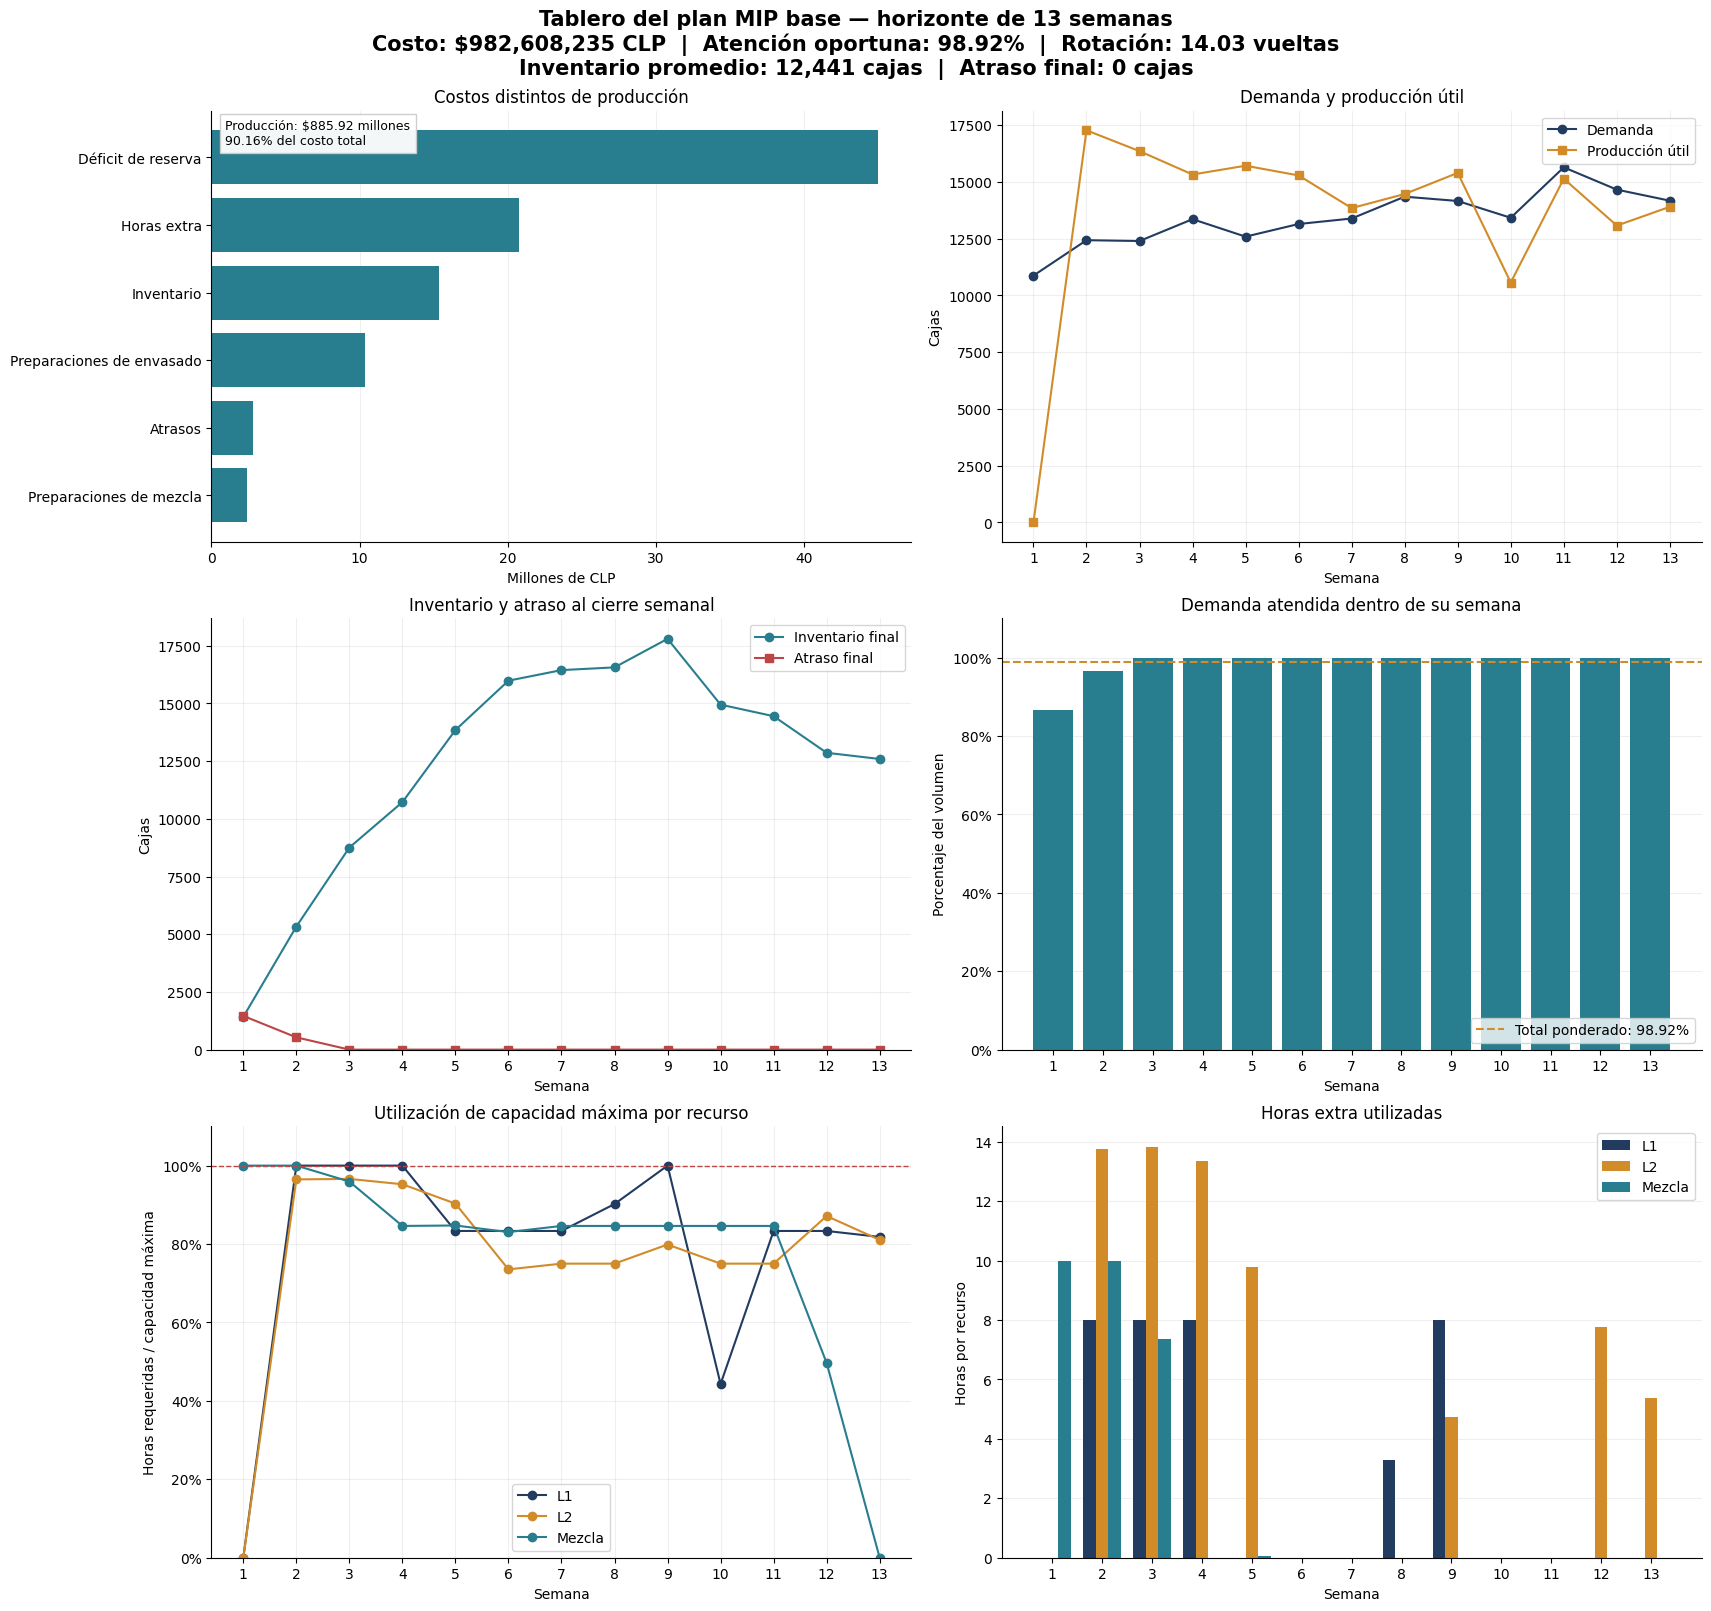

Capacidad máxima = horas regulares + máximo de horas extra permitido.
Atención oportuna estimada suponiendo prioridad a los pedidos más antiguos.
Plan factible verificado; optimalidad global no demostrada.
Imagen guardada en: resultados_entrega2/tablero_plan_base.png


In [39]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

with plt.rc_context({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
}):
    fig, ejes = plt.subplots(
        3, 2,
        figsize=(17, 16),
        constrained_layout=True,
    )

    fig.suptitle(
        "Tablero del plan MIP base — horizonte de 13 semanas\n"
        f"Costo: ${costo_total_tablero_base:,.0f} CLP  |  "
        f"Atención oportuna: {atencion_oportuna_base_pct:.2f}%  |  "
        f"Rotación: {rotacion_base:.2f} vueltas\n"
        f"Inventario promedio: {inventario_promedio_base:,.0f} cajas  |  "
        f"Atraso final: {atraso_final_base:,.0f} cajas",
        fontsize=15,
        fontweight="bold",
    )

    # 1. Costos distintos de producción.
    ax = ejes[0, 0]

    costos_operativos = costos_tablero_base.loc[
        costos_tablero_base["Componente"] != "Producción"
    ].sort_values("Costo_CLP")

    ax.barh(
        costos_operativos["Componente"],
        costos_operativos["Costo_CLP"] / 1e6,
        color="#287D8E",
    )
    ax.set_title("Costos distintos de producción")
    ax.set_xlabel("Millones de CLP")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    fila_produccion = costos_tablero_base.loc[
        costos_tablero_base["Componente"] == "Producción"
    ].iloc[0]

    ax.text(
        0.02, 0.98,
        f"Producción: ${fila_produccion['Costo_CLP'] / 1e6:,.2f} millones\n"
        f"{fila_produccion['Participacion_pct']:.2f}% del costo total",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="#CCCCCC", alpha=0.95),
    )

    # 2. Demanda y producción útil.
    ax = ejes[0, 1]
    semanal = resumen_semanal_base.sort_values("Semana")

    ax.plot(
        semanal["Semana"],
        semanal["Demanda_cajas"],
        marker="o",
        label="Demanda",
        color="#223B60",
    )
    ax.plot(
        semanal["Semana"],
        semanal["Produccion_util_cajas"],
        marker="s",
        label="Producción útil",
        color="#D18B28",
    )
    ax.set_title("Demanda y producción útil")
    ax.set_xlabel("Semana")
    ax.set_ylabel("Cajas")
    ax.set_xticks(SEMANAS)
    ax.legend()
    ax.grid(alpha=0.2)

    # 3. Inventario y atrasos.
    ax = ejes[1, 0]
    ax.plot(
        semanal["Semana"],
        semanal["Inventario_final_cajas"],
        marker="o",
        label="Inventario final",
        color="#287D8E",
    )
    ax.plot(
        semanal["Semana"],
        semanal["Atraso_final_cajas"],
        marker="s",
        label="Atraso final",
        color="#BD4545",
    )
    ax.set_title("Inventario y atraso al cierre semanal")
    ax.set_xlabel("Semana")
    ax.set_ylabel("Cajas")
    ax.set_xticks(SEMANAS)
    ax.set_ylim(bottom=0)
    ax.legend()
    ax.grid(alpha=0.2)

    # 4. Atención oportuna.
    ax = ejes[1, 1]
    ax.bar(
        semanal["Semana"],
        semanal["Atencion_oportuna_pct"],
        color="#287D8E",
    )
    ax.axhline(
        atencion_oportuna_base_pct,
        linestyle="--",
        color="#D18B28",
        label=f"Total ponderado: {atencion_oportuna_base_pct:.2f}%",
    )
    ax.set_title("Demanda atendida dentro de su semana")
    ax.set_xlabel("Semana")
    ax.set_ylabel("Porcentaje del volumen")
    ax.set_xticks(SEMANAS)
    ax.set_ylim(0, 110)
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend(loc="lower right")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    # 5. Utilización de capacidad máxima.
    ax = ejes[2, 0]

    colores = {
        "L1": "#223B60",
        "L2": "#D18B28",
        "Mezcla": "#287D8E",
    }

    for recurso, color in colores.items():
        tabla_recurso = detalle_recursos_base.loc[
            detalle_recursos_base["Recurso"] == recurso
        ].sort_values("Semana")

        ax.plot(
            tabla_recurso["Semana"],
            tabla_recurso["Uso_sobre_maxima_pct"],
            marker="o",
            label=recurso,
            color=color,
        )

    ax.axhline(100, color="#BD4545", linestyle="--", linewidth=1)
    ax.set_title("Utilización de capacidad máxima por recurso")
    ax.set_xlabel("Semana")
    ax.set_ylabel("Horas requeridas / capacidad máxima")
    ax.set_xticks(SEMANAS)
    ax.set_ylim(0, 110)
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend()
    ax.grid(alpha=0.2)

    # 6. Horas extra por recurso y semana.
    ax = ejes[2, 1]

    tabla_extras = detalle_recursos_base.pivot(
        index="Semana",
        columns="Recurso",
        values="Extra_utilizada_h",
    ).reindex(index=SEMANAS, columns=["L1", "L2", "Mezcla"])

    posiciones = np.arange(len(SEMANAS))
    ancho = 0.25

    for desplazamiento, recurso in zip(
        [-ancho, 0, ancho], ["L1", "L2", "Mezcla"]
    ):
        ax.bar(
            posiciones + desplazamiento,
            tabla_extras[recurso],
            width=ancho,
            label=recurso,
            color=colores[recurso],
        )

    ax.set_title("Horas extra utilizadas")
    ax.set_xlabel("Semana")
    ax.set_ylabel("Horas por recurso")
    ax.set_xticks(posiciones)
    ax.set_xticklabels(SEMANAS)
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    ruta_tablero = carpeta_resultados_B / "tablero_plan_base.png"
    fig.savefig(ruta_tablero, dpi=180, bbox_inches="tight")
    plt.show()

print(
    "Capacidad máxima = horas regulares + máximo de horas extra permitido."
)
print(
    "Atención oportuna estimada suponiendo prioridad "
    "a los pedidos más antiguos."
)
print(
    "Plan factible verificado; optimalidad global no demostrada."
)
print("Imagen guardada en:", ruta_tablero)

### Interpretación del tablero y recomendaciones

**Desempeño del plan**

El plan base presenta un costo de **$982.608.235 CLP**, una atención oportuna del **98,92 %** y ningún atraso pendiente al finalizar la semana 13. Los atrasos se concentran en las dos primeras semanas y quedan resueltos en la tercera.

La ausencia de producción de envasado en la primera semana se explica por el plazo de preparación del jarabe y el supuesto de disponibilidad inicial nula de este insumo. Por ello, conviene validar dicho supuesto antes de implementar el plan: disponer de jarabe preparado previamente podría modificar los resultados iniciales.

**Inventarios y reservas**

El inventario promedio es de **12.441,29 cajas**, con una rotación de **14,03 vueltas durante las 13 semanas**. El inventario aumenta hasta la semana 9 y luego disminuye, manteniendo las reservas terminales exigidas por el modelo.

El **80,34 % de las combinaciones SKU-semana** alcanza su reserva de seguridad. Este porcentaje no equivale al nivel de servicio: mide el cumplimiento de una meta de inventario. La penalización por déficit de reserva alcanza **$45.020.666 CLP**, por lo que se recomienda revisar las combinaciones con mayores déficits y las estimaciones de incertidumbre que originan sus reservas.

**Capacidad y horas extra**

El plan utiliza **35,29 horas extra en L1**, **68,61 en L2** y **27,43 en mezcla**. L1 alcanza su capacidad máxima en las semanas **2, 3, 4 y 9**, mientras que mezcla lo hace en las semanas **1 y 2**.

Se recomienda asegurar anticipadamente la disponibilidad de personal y recursos en esas semanas. La holgura acumulada del horizonte no permite sustituir automáticamente capacidad de una semana por otra, debido a los plazos, inventarios y compromisos de producción.

**Criterio económico para decidir**

La elección entre anticipar producción, utilizar horas extra o aceptar un atraso debe comparar costos incrementales para una misma cantidad de producto:

- **Anticipar producción:** considerar el costo de mantener inventario durante las semanas adicionales, los cambios en preparaciones y la capacidad disponible anteriormente.
- **Utilizar horas extra:** considerar las horas adicionales requeridas en envasado y mezcla, sus tarifas y las preparaciones que correspondan.
- **Aceptar un atraso:** considerar la penalización por caja y semana, además de un posible incremento del déficit de reserva.

Por ejemplo, mantener una caja adicional durante una semana cuesta **$95 CLP**, mientras que atrasarla una semana cuesta **$1.400 CLP**. Esto favorece anticipar producción cuando sea factible y los demás costos incrementales no superen el ahorro. No obstante, la comparación debe incorporar conjuntamente las capacidades y los costos de preparación.

**Recomendación final**

Se propone utilizar el plan MIP base como referencia táctica, porque obtuvo un costo **$16.048.990 CLP menor** que el lote por lote reparado y superó la verificación de restricciones.

Antes de ejecutarlo, deben validarse los supuestos iniciales y comprobarse la secuenciación detallada, ya que los tiempos de preparación utilizados en este modelo son aproximaciones tácticas. Además, la solución terminó por límite de tiempo, con una brecha aproximada de **0,534 %**; por tanto, se considera factible respecto del modelo, pero no de optimalidad global demostrada.